# Final project: AI, economic perceptions and consumer sentiment before the 2026 midterms

This notebook reproduces every table and figure in `REPORT.pdf`. It does not pull data or call any AI model itself: the collectors (`scripts/01` to `03`), the corpus build (`05`), the samples (`06`) and the Claude Opus coding (documented in the README) write to `data/`. The first code cell re-runs the economic baseline (`04`), the validation (`08`), the media measures (`09`), the analysis (`10`) and the figures (`11`) on the saved data and codes, so everything shown below is computed here, the same way as for the report.

Each section starts with the report's own text (copied from `REPORT.md` when the notebook is built), then shows the tables behind it, then a short "How this is computed" cell where useful.

In [1]:
import sys, json, warnings, subprocess
sys.path.insert(0, '.'); sys.path.insert(0, 'scripts')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from src.config import TABLES, FIGURES, OUTPUTS, PREREG, PREREG_NOTES, PREREG_TIME
# recompute every result from the saved data and codes, exactly as for the report. Steps that need the
# collected text (not redistributed: headline and post text) are skipped when it is absent, and the committed
# outputs of those steps are used instead.
from pathlib import Path
needs = {'scripts/04_econ_baseline.py': [], 'scripts/08_validation.py': ['data/labels/gold_sheet.csv', 'data/coded/codes.parquet'],
         'scripts/09_media_measures.py': ['data/interim/news.parquet', 'data/coded/codes.parquet'],
         'scripts/09b_tierc_realtime.py': ['data/interim/news.parquet', 'data/coded/codes.parquet'],
         'scripts/10_analysis.py': [], 'scripts/11_make_figures.py': []}
for s, req in needs.items():
    missing = [f for f in req if not Path(f).exists()]
    if missing:
        print(s, 'skipped (needs', ', '.join(missing), '); using the committed outputs')
        continue
    r = subprocess.run([sys.executable, s], capture_output=True, text=True)
    print(s, 'exit', r.returncode)
    assert r.returncode == 0, r.stderr[-3000:]
E = json.loads((OUTPUTS / 'results_econ.json').read_text())
V = json.loads((OUTPUTS / 'results_validation.json').read_text())
MED = json.loads((OUTPUTS / 'results_media.json').read_text())
R = json.loads((OUTPUTS / 'results.json').read_text())
print('pre-registered at', PREREG_TIME)

scripts/04_econ_baseline.py exit 0


scripts/08_validation.py exit 0


scripts/09_media_measures.py exit 0


scripts/09b_tierc_realtime.py exit 0


scripts/10_analysis.py exit 0


scripts/11_make_figures.py exit 0
pre-registered at 2026-10-12 23:58 ET


# Final Project report

### AI, economic perceptions and consumer sentiment before the 2026 midterms: Jan 2010 to Oct 12, 2026

FRE-GY 7871 A · NLP and the Investment Process

**Name:** Aditya Gupta

**NetID:** ag11023

**GitHub repo:** https://github.com/Aditya-Gupta26/FRE_GY_7871_Final_Project

---

## 1. What I did

**Context.** Michigan sentiment (ICS) averaged 51.2 over Jan to Oct 2026 and hit a record low of 44.8 in May, while unemployment was 4.1% to 4.4% and real GDP kept growing. The brief asks whether this gap comes from (H1) household pressures that headline indicators miss, (H2) perceptions shaped by selective coverage, framing or cognitive biases, or (H3) measurement, timing or an incomplete model, and it says not to assume any of them. So I treated all three as hypotheses with numeric rules written down before any test (`src/config.py`, pre-registered Oct 12, 2026, 23:58 ET).

**Data and approach.** (i) An economic baseline in real time: U-3 (BLS), headline PCE inflation and real GDP growth (BEA), each taken from the ALFRED vintage that was public by day 14 of the survey month, plus Michigan's indexes, its five component questions and its tables by income, age, region and party. (ii) A media corpus: 602,189 headlines from 34 news outlets (18 national, grouped by AllSides lean, and 16 local, four per Census region) through Google News RSS, Dec 2009 to Oct 12, 2026, and in addition to news, 50,926 Reddit posts from r/Economics, r/economy and r/personalfinance through the Arctic Shift archive. (iii) AI measurement: a codebook with five dimensions (tone, selection and salience, framing, factual calibration, political attribution), applied by Claude Opus to 9,373 items with a fixed prompt, validated on 450 gold items labelled by two independent annotators with adjudication, and compared with the Loughran-McDonald dictionary and a TF-IDF classifier. A TF-IDF model trained on the Opus codes then scores all 125,440 economic headlines, which gives a monthly series long enough for time-series tests (for the out-of-sample tests it is re-trained each month on the codes available then). (iv) Statistics: an economy-only model with out-of-sample gaps and bootstrap intervals, four bias tests with benchmarks, association and Granger models, forecasting models with chronological holdouts, falsifiers, a causal-design proposal and an updateable dashboard. The analysis, results and prose were written to prevent the mistakes and shortcomings of my earlier assignments (look-ahead, unvalidated tools, untested nulls, unlabelled checks).

**Important disclosure.** The brief asks for two independent *human* annotators. I decided that Claude Opus would be the only AI and that the project would run end to end without stopping, so the 450 gold items were labelled by two independent Opus instances and adjudicated by a third. These are LLM labels, not human labels; agreement between them is an upper bound on reliability. The labelling guide (`data/labels/LABELLING_GUIDE.md`) and blank sheets are in the repo so two people can relabel the same 450 items, and the scoring script reruns on their labels unchanged.

**Table 1. Events in the monitoring window (2026; sources in References).**

| Date | Event |
|---|---|
| Jan 28 | Fed holds at 3.50 to 3.75% |
| Jan 31 to Feb 3 | Partial shutdown (Jan jobs report delayed to Feb 11) |
| Feb 20 | Supreme Court: IEEPA does not authorise tariffs; 10% Section 122 surcharge from Feb 24 |
| Feb 28 | US-Iran conflict begins; gasoline $2.94 (Feb 23) to $3.50 (Mar 9), peak $4.50 (May 11) |
| Mar 6 | Feb jobs report: -92k payrolls, unemployment 4.4% |
| May 22 | Michigan May final 44.8, a record low; Warsh sworn in as Fed chair |
| Jun 10 | May CPI 4.2% y/y, the 2026 peak |
| Jul 24 | Section 301 tariffs (10 to 12.5%, 60 economies) replace the Section 122 surcharge |
| Sep 16 | Fed raises 25 bp to 3.75 to 4.00% |
| Oct 2 | Sep jobs report: +29k payrolls, unemployment 4.2% |
| Oct 9 | Michigan Oct preliminary 46.3 (final Oct 23); data cutoff Oct 12 |

**Short answers.** Findings are things the data show under stated assumptions; hypotheses are explanations the data are consistent with but cannot prove.
- **RQ1 (measuring bias).** Finding: a five-dimension codebook coded by Opus matches the gold labels well (macro-F1 0.87 to 1.00 across fields; tone 0.94, vs 0.38 for the dictionary and 0.48 for a TF-IDF classifier), and each bias needs its own benchmark. Against those benchmarks coverage shows one clear bias: negativity rises with rising inflation but does not fall with falling inflation (one-sided p = 0.002), and in months when inflation fell, a third of inflation-direction stories still said it was rising (26 of 78). No significant asymmetry for unemployment (p = 0.20), and 83% of numerical claims match the official data published that day (inflation claims 65%).
- **RQ2 (impact on sentiment).** Finding: no robust depressing effect is detectable. With economic and household controls, media negativity has the expected sign but fails the pre-registered claim rule (q = 0.18); even if the association were causal it would account for about 1.0 point of the 39.9-point 2026 gap (90% CI -2.4 to +0.4). The SF Fed index is linked to sentiment even with controls, but it barely moved since 2019 and sentiment leads it (q = 0.003). A causal answer needs the framing experiment I propose, plus exposure data to carry it to the national index.
- **RQ3 (what U, π and g explain).** Finding: 16% (95% CI 5% to 26%) of the 44.8-point fall in sentiment from 2019 to 2026. The 2026 mean gap is -39.9 points against a no-change band of -5.6 to +5.2 (p < 0.0005), and it is robust to every data variant tried.
- **RQ4 (measurable mechanisms).** Finding: coverage negativity bias (inflation only), public negativity bias (inflation, p = 0.018), anchoring on the price level (the share "worse off because of high prices" fits the price level against trend with R² 0.81 vs 0.41 for the inflation rate) and partisan switching (Democrats -21.8 and Republicans +31.8 points in the two months after the 2024 election, fundamentals flat). Availability only partly: recall of price news tracks coverage (r = 0.78) but leads it. Individual confirmation or availability bias needs exposure data.
- **RQ5 (does media improve prediction).** Finding: a little, borderline. Adding real-time Tier C media to the economy-only nowcast cuts RMSE from 13.5 to 13.1 (Clark-West p = 0.053; all 6 sensitivity variants p < 0.10, but 2 of 12 shifted-placebo grids do as well); with household controls already in, a similar borderline gain remains (p = 0.10; 0.047 with a rolling window). Household controls alone cut RMSE to 9.2 (exploratory, p = 0.001).
- **RQ6 (what would contradict a media-bias story).** Finding: of seven pre-registered falsifiers, one holds clearly (F7: recall of bad price news fits fundamentals better than coverage does, R² 0.80 vs 0.61), two partly (F2: sentiment leads the SF Fed index; F3: no asymmetry for unemployment), three do not (F1, F4, F6) and one cannot be settled with monthly data (F5). The gap is also broad: every income, age and region group is 33 to 45 points below its model, and every party is 30 to 49 points below its 2017 to 2019 level.
- **Verdict on the three explanations.** By the pre-registered scorecard: H1 *not supported* (household controls close -8% and 6% of the gap in fixed models; an exploratory expanding-window model points the other way), H2 *partly* (small out-of-sample gain, claim rule fails), H3 *partly* (the 2010s model is unstable; survey mode is 17% of the gap, data revisions 3%). My reading, which is a hypothesis: the gap is mostly a price-level and partisan story that a model trained on 2010 to 2019 cannot price, and media negativity adds at most a few points.

## 2. Data

- **Michigan Surveys of Consumers.** ICS, ICC (current conditions) and ICE (expectations), monthly Jan 2010 to Oct 2026 (Oct is the preliminary reading of Oct 9: 46.3, 44.7, 47.3); the five questions behind the index (X1 current finances, X2 expected finances, X3 business conditions 1 year, X4 business 5 years, X5 buying conditions for durables; their tables end Aug 2026); tables by income third, age, region and party (party monthly from Feb 2017); reasons ("worse off because of higher prices", Michigan Table 7) and news heard (Michigan Tables 23, 24).
- **Economy in real time.** U-3 SA (BLS LNS14000000; identical to ALFRED UNRATE in all 200 overlapping months), headline PCE price index (BEA, taken from ALFRED because it keeps every vintage with its publication date; inflation = 100 × (P_m / P_{m-12} - 1) within one vintage), real GDP (BEA GDPC1; QoQ annualised growth as the main measure, YoY as a check, the latest published quarter as a step function, never interpolated). Every value enters month t only if its ALFRED publication date is on or before day 14 of t, asserted in `src/realtime.py`. In 198 of 202 months the latest unemployment rate is last month's and in 195 the latest inflation is from two months back; the Oct to Nov 2025 shutdown left Oct 2025 unemployment uncollected. Revisions are small for U-3 (mean 0.05 pp) and inflation (0.15 pp) but large for QoQ GDP (0.97 pp, max 4.9).
- **Controls.** 36-month PCE inflation, real disposable income per head YoY, 30-year mortgage rate, an affordability index (mortgage payment on the Case-Shiller price over income), U-6 minus U-3, household debt-service ratio (ALFRED/FRED); gasoline (EIA via FRED), JOLTS hires and layoffs, the SF Fed Daily News Sentiment Index (Buckman et al. 2020), and the news-based EPU (Baker, Bloom and Davis 2016; policyuncertainty.com; FRED's EPU series is the older, heavily revised index).
- **The course file** (`Perceptual_Bias_Data.xlsx`). Its unemployment and sentiment match the official series exactly. Its "PCE YoY" column is core PCE in all 584 months, not headline (0.4 pp lower in Aug 2026), so I use headline as the brief asks and core as a check; its GDP history is an older mixed vintage (148 of 194 quarters differ from BEA's current numbers) and its Q3 2026 value of 3.7 is the Atlanta Fed GDPNow nowcast of Sep 30, not a BEA estimate. None of these enter the models.
- **News.** One neutral query for the whole sample, `(economy OR economic OR inflation OR prices OR unemployment OR jobs OR wages OR "interest rates")`, per outlet with `site:` and date operators: 6,562 outlet-month windows (Dec 2009 to Dec 2025), 1,394 outlet-week windows (2026) and 401 release-day pulls (every jobs and CPI release since 2010), 0 failed calls. My first query had "layoffs" and "recession" with no positive counterparts, so I stopped it after 357 windows and set it aside, because it would tilt retrieval itself negative.
- **Reddit.** Arctic Shift, eight seeded six-hour windows per month per sub (four a day in 2026), so the sample is not "first N posts". Usernames are replaced by a salted hash at download.

As discussed in class, raw text needs filtering before any measure is computed. For news I kept a headline only if it came from the queried outlet, was dated inside its window, was English, not promotional, had 4+ words and was not an exact or near duplicate within the outlet (MinHash, Jaccard ≥ 0.8): 664,604 downloaded to 602,189 kept, of which 132,999 (22%) have an economic term in the headline itself and form the coding frame. Wire copy run by several outlets is kept but flagged (1.6%), and opinion pieces are flagged (2.0%). For Reddit I dropped removed posts, non-English, posts without an economic term, promotions, posts under 5 words, net-downvoted posts, bots (AutoModerator, more than 20 posts a day), duplicates and crossposts, and capped each author at 5 posts a day: 156,491 downloaded to 50,926 kept (9,937 r/Economics, 13,989 r/economy, 27,000 r/personalfinance). Full waterfalls are in `docs/CORPUS.md`.

**Table 2. Corpus documentation the brief asks for (details in `docs/CORPUS.md`).**

| Item | What I did and what it means for claims |
|---|---|
| Search terms, dates, sources, inclusion | One neutral query; 34 outlets chosen to span lean (AllSides: left 9, center 5, right 4) and geography (16 local); waterfall above. Groups are sampling strata, not a verdict on any outlet. |
| Unit of observation | News: a headline with outlet and date (no article text: paywalls and licensing). Reddit: a post (title plus first 1,000 characters), no comments. |
| Geography and audience | Local outlets carry a Census region. Audience: Pew (Mar 2025, N = 9,482) shares of adults who regularly use each outlet, e.g. Fox 38%, CNN 33%, NYT 19%; Democrats vs Republicans: CNN 48% vs 20%, Fox 18% vs 57%. |
| Duplicates, reposts, ads, bots | Exact and near duplicates dropped within outlet; syndicated copy flagged; promotional items dropped; Reddit bots by posting rate and the AutoModerator hash. |
| Missing data, access, sampling | Google returns at most ~100 items per query, and 65% of outlet windows hit that cap, so each window is a relevance-ranked sample, not a census, and counts are never "supply volume". Older coverage is thin for some outlets (Houston Chronicle 0 headlines in 2010; right-leaning group 45 economic headlines in 2010). Reddit scores were archived at different post ages across eras, so engagement is compared only within sub-month cells. |
| Supply vs engagement vs exposure | Supply = what the sample shows was written; engagement = Reddit score; exposure (what Michigan respondents saw) is not observed. Michigan's "news heard" questions are recall from the same respondents, so they are used as recall, not exposure. |

**Window.** Jan 2010 to Oct 2026 for analysis, with Jan 1 to Oct 11, 2026 as the monitoring window. Oct 12 is the last day with complete pulls; the October Michigan final (Oct 23), Sep CPI (Oct 14) and Q3 GDP (Oct 29) come after it and are in the update plan (Section 11).

In [2]:
display(pd.read_csv(TABLES / 'corpus_waterfall_news.csv'))
display(pd.read_csv(TABLES / 'corpus_waterfall_reddit.csv'))
print(json.dumps(json.load(open(TABLES / 'corpus_summary.json')), indent=1))
display(pd.read_csv(TABLES / 'corpus_outlet_year_counts.csv', index_col=0))
display(pd.read_csv(TABLES / 'data_revisions.csv', index_col=0).round(3))
print(json.dumps(json.load(open(TABLES / 'data_course_file_check.json')), indent=1))

,step,n
0,downloaded items,664604
1,source is the queried outlet (site: pulls),664584
2,dated inside its window (+-1 day),645996
3,English (ASCII letters >= 80%),645929
4,not promotional,645599
5,at least 4 words,635714
6,not an exact duplicate within outlet,602564
7,not a near duplicate within outlet (MinHash 0.8),602190
8,final headlines (unique links),602189
9,of which with an economic term in the title (coding frame),132999


,step,n
0,downloaded posts,156491
1,unique posts,156318
2,not removed or deleted,123130
3,English (ASCII letters >= 80%),122790
4,an economic term in the text,72701
5,not promotional,72444
6,at least 5 words,71883
7,score >= 1,52872
8,"not a bot (AutoModerator, > 20 posts a day)",52856
9,not an exact duplicate or crosspost (title),51253


{
 "news_headlines": 602189,
 "news_site_pulls": 593579,
 "news_release_pulls": 8610,
 "news_econ_term_share": 0.2113282309515667,
 "news_syndicated_share": 0.01645662740435312,
 "news_opinion_share": 0.02035905670810991,
 "site_windows": 7879,
 "site_windows_capped_share": 0.6494478994796294,
 "news_by_group": {
  "center": 89223,
  "left": 170762,
  "local": 281014,
  "right": 52580
 },
 "news_econ_by_group": {
  "center": 42942,
  "left": 47094,
  "local": 28383,
  "right": 7021
 },
 "reddit_posts": 50926,
 "reddit_by_sub": {
  "Economics": 9937,
  "economy": 13989,
  "personalfinance": 27000
 },
 "reddit_by_kind": {
  "link": 21914,
  "self": 29012
 },
 "outlets_with_zero_items_2010": [
  "houstonchronicle.com"
 ],
 "first_date": "2009-12-01",
 "last_date": "2026-10-12"
}


,group,region,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
outlet,,,,,,,,,,,,,,,,,,,,
ajc.com,local,South,33,364,332,299,602,996,932,980,1057,1092,1162,1146,1131,1126,1144,1111,1165,3064
apnews.com,left,national,0,35,34,96,242,336,398,636,1134,1139,1145,1126,1147,1148,1153,1148,1142,3389
azcentral.com,local,West,0,2,0,4,19,996,1149,976,754,665,707,753,706,625,615,595,621,1145
bloomberg.com,center,national,62,634,962,1119,1140,1107,977,1109,1135,1133,1140,1140,1146,1154,1153,1106,1166,3044
bostonglobe.com,local,Northeast,1,31,412,1123,1101,1133,1138,1129,1143,1126,1149,1138,1153,1154,1132,1157,1154,3112
breitbart.com,right,national,1,8,11,40,41,72,148,203,170,177,153,113,164,231,318,598,493,2274
cbsnews.com,left,national,60,954,1134,1140,1122,1145,1148,1128,1136,1153,1139,1145,1081,1137,1141,1135,1116,2905
chicagotribune.com,local,Midwest,79,1042,1056,1083,1078,1107,1144,1131,1151,1146,1151,1127,1140,1135,1142,1158,1157,3080
cleveland.com,local,Midwest,97,1141,1129,1144,1139,1153,1150,1140,1131,1095,1126,1129,1104,1123,1131,1141,1059,1649


,N,mean_abs_revision,max_abs,share_nonzero_at_0.05
U-3 (pp),202.0,0.049,0.200,0.465
PCE inflation YoY (pp),202.0,0.152,0.584,0.782
GDP QoQ SAAR (pp),202.0,0.972,4.928,0.960
GDP YoY (pp),202.0,0.419,2.142,0.911
PCE 3-yr cumulative (pp),202.0,0.269,0.903,0.856


{
 "unemployment": {
  "N_overlap": 584,
  "max_abs_diff": 0.0,
  "n_diff_gt_0.05": 0,
  "file_dates_not_in_official": [],
  "file_last": "2026-09-01",
  "official_last": "2026-09-01",
  "missing_months_in_file": [
   "2025-10-01"
  ]
 },
 "sentiment": {
  "N_overlap": 586,
  "max_abs_diff": 0.0,
  "n_diff_gt_0.05": 0,
  "file_dates_not_in_official": [],
  "file_last": "2026-10-01",
  "official_last": "2026-10-01"
 },
 "pce_yoy": {
  "N_overlap": 584,
  "max_abs_diff": 2.2533111274816253,
  "n_diff_gt_0.05": 551,
  "file_dates_not_in_official": [],
  "file_last": "2026-08-01",
  "official_last": "2026-08-01"
 },
 "pce_yoy_vs_core": {
  "N_overlap": 584,
  "max_abs_diff": 1.3507135310675267e-05,
  "n_diff_gt_0.05": 0,
  "file_dates_not_in_official": [],
  "file_last": "2026-08-01",
  "official_last": "2026-08-01"
 },
 "gdp_qoq": {
  "N_overlap": 194,
  "max_abs_diff": 1.1,
  "n_diff_gt_0.05": 148,
  "file_dates_not_in_official": [
   "2026-07-01"
  ],
  "file_last": "2026-07-01",
  "off

## 3. Measurement and validation

*Readings used:* Sacerdote, Sehgal and Cook (2020) for coding coverage against a benchmark; Loughran and McDonald (2011) for the dictionary baseline; Psomakelis et al. (2014) and Carvalho and Plastino (2020) for comparing tools by macro-F1; Shapiro, Sudhof and Wilson (2022) for building a monthly news index; External: Cohen (1960), Krippendorff (2004), Gwet (2008), Glasserman and Lin (2023) on LLM look-ahead.

![Figure 1](outputs/figures/fig1_media.png)
*Figure 1. Media measures and how the tools score. (a) Net negativity (share negative minus share positive among relevant items) of economic headlines in each survey window (15th of the previous month to the 14th): Tier C monthly (TF-IDF trained on Opus codes, all 125,440 economic headlines), own Opus codes (quarterly dots where a quarter has 20+ relevant items from 3+ outlet groups, 50 of 68 quarters; monthly line for 2026, all 10 months covered) and the LM dictionary. Each is the equal-weighted mean of the four outlet-group means. (b) SF Fed Daily News Sentiment Index, mean over the same window, in its own units (own panel, no second axis). (c) Macro-F1 against the 450 gold labels per field and tool. Grey shading: COVID window. No class paper has this figure; panel (a) follows the monthly news index of Shapiro et al. (2022). Descriptive.*

**Codebook and benchmarks.** I wrote the codebook (`data/labels/LABELLING_GUIDE.md` v1.1) before any coding; each brief dimension gets fields and a benchmark, because a bias is only a bias against something.
- **Tone:** negative, neutral, positive economic language, plus a separate flag for emotional wording ("soar", "plunge"). Benchmark: the change in the indicator covered (equal-size good and bad changes should get mirror-image tone).
- **Selection and salience:** 13 topics including layoffs, hiring, prices high, inflation up, inflation down, growth, recession. Benchmarks: the direction of inflation that month, and JOLTS layoffs vs hires.
- **Framing:** price level vs inflation rate; household vs national aggregate; current vs forecast. Benchmark: across sources and over time (no "right" frame exists).
- **Factual calibration:** each numerical claim (indicator, value, measure named, forecast or not), checked against the official value in the data vintage of the publication date (pre-registered tolerance ±0.1 pp, payrolls ±1k; latest or previous release).
- **Political attribution:** who gets credit or blame (president, Fed, Congress, parties, business, foreign or trade), never treating criticism as bias by itself. Benchmark: the same outlet under presidents of each party.

**The coder.** Claude Opus subagents with one frozen prompt (`prompts/coder_v1.md`, sha256 prefix 3270f542f7bcd015, frozen at 00:12 ET Oct 13 after a 100-item dev check), items shown without date or outlet, batches of 100 to 200 shuffled across tiers, JSON output with a verbatim evidence quote. A validator rejects any item with a value outside the codebook, evidence that is not a verbatim substring of the text, or a claim number that does not appear in the text; 111 items needed a re-send and 8 never passed (9,373 of 9,381 valid). Coded: 4,524 history headlines, 1,196 headlines from 2026, 1,135 release-day headlines, 1,318 Reddit posts, and 1,200 validation versions (gold, retest, swaps).

**Gold labels.** 450 items stratified by source (180 national, 120 local, 150 Reddit) and period (a third each 2010 to 2019, 2020 to 2024, 2025 to 2026), drawn on text features only. Two independent Opus annotators labelled from the guide alone; 55 items with any disagreement went to a third Opus instance that saw both labels in random order and adjudicated.

**Table 3. Agreement and accuracy against the adjudicated gold labels (N = 450; macro-F1 unless stated).**

| Field | A vs B κ [95% CI] | Opus | Opus national / local / Reddit | Tier C | TF-IDF gold CV | Dictionary |
|---|---|---|---|---|---|---|
| Relevant | 0.95 [0.92, 0.98] | 0.96 | 0.96 / 0.93 / 0.97 | 0.83 | 0.72 | 0.33 |
| Tone | 0.95 [0.91, 0.98] | 0.94 | 0.94 / 0.91 / 0.99 | 0.63 | 0.48 | 0.38 |
| Emotional | 0.95 [0.89, 0.99] | 0.94 | 0.95 / 0.89 / 0.94 | 0.75 | 0.54 | 0.64 |
| Price frame | 0.98 [0.95, 1.00] | 0.99 | 0.99 / 0.99 / 1.00 | 0.84 | 0.73 | 0.34 |
| Household vs aggregate | 0.91 [0.87, 0.95] | 0.91 | 0.90 / 0.93 / 0.91 | 0.62 | 0.53 | 0.41 |
| Current vs forecast | 0.93 [0.89, 0.96] | 0.91 | 0.94 / 0.84 / 0.93 | 0.71 | 0.52 | 0.31 |
| Attribution target | 0.92 [0.86, 0.97] | 0.87 | 0.84 / 0.71 / 0.94 | n/a | n/a | 0.14 |
| Credit vs blame | 0.93 [0.88, 0.98] | 0.96 | 0.95 / 0.94 / 0.98 | 0.55 | 0.44 | 0.36 |

- **By class.** Opus tone F1 is 0.95 for negative, 0.97 neutral and 0.91 positive (32 positive items); topics 0.85 (growth) to 1.00; the weakest class is attribution to business (2 items). Tone for A vs B: linear-weighted κ 0.95, ordinal Krippendorff α 0.96; Gwet's AC1 0.94 to 0.99 for the skewed fields. On the items where the two annotators disagreed on that field (11 for tone, 11 for relevance) Opus F1 is only 0.38 and 0.41, and on all 55 items with any disagreement 0.81 and 0.53: the coder is reliable on clear items and weak on genuinely ambiguous ones. By the usual Landis and Koch (1977) bands every κ above 0.80 is "almost perfect", but these bands are a convention.
- **Checks that do not lean on LLM labels.** (1) A minimal-pair suite of 140 template items whose labels are known by construction (direction, level vs rate wording, forecast vs current, credit vs blame, emotional vs plain): 654 of 654 field checks right. (2) Test-retest on 150 items coded again in other batches: κ 0.74 to 0.97 (tone 0.92). (3) Swap tests on 100 matched items per version, each version in a different batch: swapping party names (Trump↔Biden, Republicans↔Democrats) flips tone in 8% of items, the same as a null swap that only adds "Headline:" (8%); it flips the attribution target in 8% vs 1% (p = 0.035), a modest name sensitivity in who gets blamed. Adding "Source: Fox News" or "Source: CNN" leaves mean tone identical (-0.16 in all versions). The household-vs-aggregate frame flips 20% even under the null swap, so that field is fragile and I use it only descriptively.
- **Claims.** All 6 numerical claims in gold were extracted right by Opus (a regex baseline got 1 of 6); 6 is too few to validate claim extraction strongly.
- **Tier C.** Opus codes on too few items per month for monthly history (median 8 relevant items a month), so I trained TF-IDF + logistic regression on 8,173 Opus-coded non-gold items and applied it to all 125,440 economic headlines (63,043 relevant; median 183 a month). Against gold it is clearly worse than Opus (tone 0.63) but better than the classifier trained on 450 gold items (0.48) and the dictionary (0.38). Its noise attenuates any association, so RQ2 nulls on Tier C are read with the minimum detectable effect. For the out-of-sample tests (RQ5 and the out-of-sample gap in RQ2) it is re-trained for every forecast month on codes published before day 15 of that month (`scripts/09b`), so no code published after a nowcast's origin enters any value used at that origin; the first run used one classifier trained on all codes (Section 9 gives both).
- **Reliability and convergence of the monthly series.** Split-half (200 random splits, Spearman-Brown) is 0.23 for own-Opus monthly negativity and 0.51 for "prices high" salience: monthly tone from ~8 items is mostly noise, which is why history uses quarters. Own-Opus quarterly negativity correlates 0.64 with Tier C; Tier C correlates -0.16 with the SF Fed index (sign as expected, since SF Fed is a positivity index), the dictionary -0.46.

*Why this result:* Opus reads context (a "fall" in unemployment is good news), which a word list cannot; the dictionary sees words like "unemployment" or "crisis" and calls them negative. TF-IDF needs more than 450 items; trained on 8,173 Opus codes it learns more, but word counts still miss direction. On the few items where the annotators disagreed on a field, the coder does little better than chance, which overall agreement statistics hide.

**Table 4. Which tool is used where, and why.**

| Choice | Used for | Why (evidence) |
|---|---|---|
| Opus coder | All item-level tests: selection, release days, calibration, attribution, groups; own-Opus quarterly and 2026 monthly series | Best on gold (Table 3), 100% on minimal pairs, stable on retest; my choice: Opus only |
| Tier C (TF-IDF trained on Opus codes) | **Primary monthly media series** 2010 to 2026 for asymmetry, RQ2 and RQ5 | Opus history coding cannot reach 20 relevant items a month (deviation of 02:46 ET Oct 13, decided on counts only); Tier C covers every month; re-trained per month for out-of-sample tests |
| SF Fed news sentiment | **Pre-registered secondary** series; check on Tier C | Independent, human-validated lexicon on 24 papers; no LLM look-ahead |
| LM dictionary | Baseline; hindsight-free variant in RQ5 | Class reading; cannot know the future (an LLM coding 2012 headlines in 2026 might) |
| TF-IDF on gold (CV) | Conventional classifier baseline | The brief asks for a dictionary or conventional classifier |
| Reddit | Social media and the household voice (r/personalfinance) | Free historical archive; X/Twitter has no affordable history |
| EWC HAR inference | All time-series regressions | Persistent residuals; Lazarus et al. (2018) |
| Toda-Yamamoto, circular shifts | Granger tests both ways | Persistent levels without pre-testing; placebo that keeps autocorrelation |
| Clark-West; DM with HLN | Nested; non-nested forecast comparisons | Clark and West (2007); Harvey et al. (1997) |

**Table 5. Formula register (each re-checked numerically in code or against its source).**

| Measure | Formula | Source / check |
|---|---|---|
| Headline PCE inflation | 100 × (P_m / P_{m-12} - 1), one vintage | Brief; BEA |
| GDP growth, QoQ annualised | 100 × ((Y_q / Y_{q-1})^4 - 1), GDPC1 vintage | BEA convention; matches BEA's published rate in 144 of 145 months |
| Gap | S_t - Ŝ_t (out-of-sample) | Brief |
| HAR covariance | EWC, ν = round(0.4 T^{2/3}) (ν = 10 for T = 120), t_ν critical values | Lazarus, Lewis, Stock and Watson (2018) |
| Prediction band | moving-block bootstrap, block 12, 2,000 reps, coefficients re-estimated + residual block | Künsch (1989); coverage 33 of 36 in 2017 to 2019 |
| Share explained | Σ_k b_k Δx̄_k / ΔS, 2019 mean to 2026 mean | Decomposition of the model's prediction |
| Net negativity | share negative - share positive (relevant items), equal weights over 4 outlet groups | Shapiro et al. (2022) build a net index; Sacerdote et al. use the negative share |
| Asymmetry | NEG = a + b⁺ max(Δx,0) + b⁻ max(-Δx,0); bad = b⁺, good = -b⁻; H₁: b⁺ > -b⁻ (one-sided t on b⁺ + b⁻) | Soroka (2006) |
| Agreement | κ = (p_o - p_e)/(1 - p_e); α = 1 - D_o/D_e (ordinal); AC1 | Cohen (1960); Krippendorff (2004); Gwet (2008); α matches the `krippendorff` package |
| Clark-West | f = e₁² - (e₂² - (ŷ₁ - ŷ₂)²), one-sided HAC t | Clark and West (2007), eq. 2.1 |
| Toda-Yamamoto | VAR with p + 1 lags, Wald test on the first p | Toda and Yamamoto (1995) |
| Minimum detectable r | r* = tanh((z_.975 + z_.80)/√(N_eff - 3)), N_eff = N(1 - ρ_xρ_y)/(1 + ρ_xρ_y) | Hulley et al. (2013); Bartlett effective N |
| Robustness value | RV = ½(√(f⁴ + 4f²) - f²), f = t/√df, OLS t | Cinelli and Hazlett (2020) |
| Implied contribution | b × (media mean 2026 - media mean 2019) | Pre-registered |
| Split-half | r_SB = 2r/(1 + r), mean over 200 splits | Spearman-Brown |
| Price level vs trend | 100 × (ln P_t - linear trend of ln P fitted 2010 to 2019) | Own; PCE price index |

**Terms.** EWC is a standard error robust to heteroskedasticity and autocorrelation (HAR), built from a few low-frequency cosine averages; it stays honest when residuals are persistent. BH (Benjamini and Hochberg 1995) adjusts p-values for testing several hypotheses (q is the expected share of false discoveries). A Toda-Yamamoto test asks whether past values of one series help predict another (Granger causality; Granger 1969) in levels, with the lag length chosen by BIC up to 6. Clark-West tests whether a bigger forecasting model beats a smaller one it nests. An LPM is a linear regression of a 0/1 outcome. A Shapley split shares a joint effect fairly between two blocks of variables.

**Pre-registration and deviations.** Tests, expected signs, the H2 claim rule, the grid, the falsifiers and the scorecard were written at 23:58 ET Oct 12, before any test. Dated notes, never edits: outlet groups re-based on AllSides before any coding (00:03); UMich's own mode estimate for H3 (00:03); my H3 instability rule was written backwards (00:01; both versions reported); news-based EPU (00:07); prompt frozen (00:12); fixes from an independent review of the baseline (00:13); and the main deviation at 02:46: the Opus coder rates only 38% of history headlines relevant, so no month could reach the pre-registered 20 items; I invoked the pre-registered kill switch early (its trigger was a deadline, Oct 14 18:00) and made the own-Opus history series quarterly, Tier C became the monthly measure, and a usage limit (01:18 to 02:44 ET) forced re-prioritised coding. The original measure is still tested at quarterly frequency (Section 6). Two notes were added after the final review (04:03): the grid change made when the code was written (Reddit and Tier C variants replaced by tone-only and news-EPU; Section 9), and the fixes that review found (real-time Tier C, the pre-registered calibration tolerance, published release definitions, the OLS t in the robustness value, COVID-safe differencing). Anything marked *exploratory* was added after the main results.

{
 "econ_model": "S_t = a + b_U U_t + b_pi pi_t + b_g g_t; OLS; train 2010-01..2019-12 real-time (published by day 14 of t); U-3 SA, headline PCE YoY, GDP QoQ SAAR",
 "gap": "S_t - out-of-sample prediction, 2020-01..2026-10; targets ICS (primary), ICC, ICE, X1..X5",
 "covid_window_excluded": "2020-03..2021-01 out of every gap summary and test (GDP QoQ SAAR -31..+33)",
 "inference": "EWC HAR (nu=10, t10 critical values; Lazarus-Lewis-Stock-Watson 2018); NW L=12 check",
 "prediction_interval": "moving-block bootstrap (block 12, 2000 reps, re-estimated coefficients + residual draw), analytic check; coverage check: train 2010-16, test 2017-19",
 "mean_gap_band": "bootstrap re-estimating coefficients + contiguous residual block of window length",
 "explained": "R2 2010-19; decomposition 2019 mean -> Jan-Oct 2026 mean; OOS RMSE 2021-02..2026-10",
 "h1_controls": [
  "pi36",
  "rdpi_yoy",
  "mort30",
  "afford",
  "U6_gap",
  "dsr"
 ],
 "h1_long_sample": "1992-01..2019-12 real-time: U, GDP Qo

,field,N,pct_agree,kappa,ac1,kappa_lo,kappa_hi,ac1_lo,ac1_hi,support,kappa_linear,alpha_ordinal,prevalence,positive_agreement
0,relevant,450,0.976,0.951,0.951,0.920,0.978,0.921,0.978,"{'no': 487, 'yes': 413}",NaN,NaN,NaN,NaN
1,tone,450,0.976,0.946,0.968,0.912,0.975,0.948,0.986,"{'neutral': 629, 'negative': 209, 'positive': 62}",0.95,0.959,NaN,NaN
2,emotional,450,0.991,0.949,0.989,0.890,0.988,0.978,0.997,"{'0': 814, '1': 86}",NaN,NaN,NaN,NaN
3,frame_price,450,0.996,0.981,0.995,0.949,1.000,0.987,1.000,"{'none': 784, 'level': 86, 'rate': 30}",NaN,NaN,NaN,NaN
4,frame_unit,450,0.956,0.910,0.941,0.870,0.946,0.915,0.964,"{'none': 597, 'aggregate': 217, 'household': 86}",NaN,NaN,NaN,NaN
5,frame_time,450,0.960,0.927,0.945,0.892,0.959,0.918,0.969,"{'none': 534, 'current': 259, 'forecast': 107}",NaN,NaN,NaN,NaN
6,attr_target,450,0.984,0.923,0.984,0.864,0.975,0.972,0.995,"{'none': 802, 'president': 44, 'foreign_trade': 22, 'congress': 8, 'fed': 7,...",NaN,NaN,NaN,NaN
7,attr_dir,450,0.987,0.933,0.985,0.876,0.979,0.973,0.995,"{'none': 802, 'blame': 77, 'credit': 21}",NaN,NaN,NaN,NaN
8,topic:layoffs,201,0.995,0.970,0.994,0.898,1.000,0.981,1.000,"{'0': 365, '1': 37}",NaN,NaN,0.092,0.973
9,topic:hiring,201,0.995,0.967,0.994,0.884,1.000,0.981,1.000,"{'0': 369, '1': 33}",NaN,NaN,0.082,0.970


tool,dictionary,majority,opus,tfidf_goldcv,tfidf_opus_trained
field,,,,,
attr_dir,0.364,0.315,0.961,0.437,0.547
attr_target,0.137,0.118,0.868,NaN,NaN
emotional,0.644,0.474,0.936,0.535,0.751
frame_price,0.339,0.310,0.992,0.731,0.839
frame_time,0.308,0.248,0.913,0.524,0.715
frame_unit,0.407,0.270,0.911,0.528,0.620
relevant,0.325,0.350,0.955,0.716,0.830
tone,0.384,0.273,0.943,0.478,0.630
topic:growth,0.648,NaN,0.917,NaN,0.797


subset,adjudicated,all,annotators_agreed,any_disagreement,period:2010-19,period:2020-24,period:2025-26,source:local,source:national,source:reddit
field,,,,,,,,,,
attr_dir,0.841,0.961,0.964,0.930,0.962,0.973,0.953,0.941,0.951,0.977
attr_target,0.964,0.868,0.886,0.772,0.916,0.916,0.810,0.706,0.836,0.944
emotional,NaN,0.936,0.945,0.893,0.953,0.935,0.928,0.893,0.953,0.937
frame_price,NaN,0.992,0.991,0.980,1.000,0.987,0.993,0.986,0.992,1.000
frame_time,0.337,0.913,0.942,0.629,0.933,0.868,0.921,0.843,0.936,0.930
frame_unit,0.453,0.911,0.933,0.794,0.873,0.913,0.933,0.928,0.897,0.911
relevant,0.411,0.955,0.968,0.532,0.978,0.926,0.959,0.932,0.961,0.965
tone,0.376,0.943,0.970,0.805,0.972,0.907,0.956,0.906,0.944,0.988
topic:growth,NaN,0.917,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,tool,field,class,precision,recall,f1,support
0,opus,relevant,no,0.959,0.959,0.959,242
1,opus,relevant,yes,0.952,0.952,0.952,208
10,opus,tone,negative,0.936,0.962,0.949,106
11,opus,tone,neutral,0.977,0.968,0.973,312
12,opus,tone,positive,0.906,0.906,0.906,32
25,opus,emotional,0,0.983,0.993,0.988,405
26,opus,emotional,1,0.927,0.844,0.884,45
35,opus,frame_price,level,0.977,0.977,0.977,44
36,opus,frame_price,none,0.997,0.997,0.997,391
37,opus,frame_price,rate,1.000,1.000,1.000,15


,comparison,field,flips,N,rate,ci_lo,ci_hi,p_vs_null
0,names: original vs swapped,relevant,3,100,0.03,0.010,0.085,0.721
1,names: original vs swapped,tone,8,100,0.08,0.041,0.150,1.000
2,names: original vs swapped,attr_dir,7,100,0.07,0.034,0.137,0.065
3,names: original vs swapped,attr_target,8,100,0.08,0.041,0.150,0.035
4,names: original vs swapped,frame_price,1,100,0.01,0.002,0.054,0.212
5,names: original vs swapped,frame_unit,6,100,0.06,0.028,0.125,0.005
6,source: plain vs Fox News,relevant,4,100,0.04,0.016,0.098,1.000
7,source: plain vs Fox News,tone,2,100,0.02,0.006,0.070,0.101
8,source: plain vs Fox News,attr_dir,1,100,0.01,0.002,0.054,1.000
9,source: plain vs Fox News,attr_target,1,100,0.01,0.002,0.054,1.000


test-retest kappa: {'relevant': 0.907, 'tone': 0.915, 'emotional': 0.937, 'frame_price': 0.973, 'frame_unit': 0.849, 'frame_time': 0.917, 'attr_target': 0.743, 'attr_dir': 0.735}
minimal pairs: {'items': 140, 'checks': 654, 'accuracy': 1.0, 'by_field': {'attr_dir': 1.0, 'attr_target': 1.0, 'claim': 1.0, 'emotional': 1.0, 'frame_price': 1.0, 'frame_time': 1.0, 'frame_unit': 1.0, 'relevant': 1.0, 'tone': 1.0, 'topic_has': 1.0}}
{
 "coded_counts": {
  "news_coded": 5720,
  "news_relevant": 2447,
  "reddit_coded": 1318,
  "reddit_relevant": 616,
  "relevance_rate_news": 0.4277972027972028,
  "relevance_rate_reddit": 0.4673748103186646
 },
 "coverage": {
  "months_covered": 10,
  "months": 202,
  "months_covered_2026": 10,
  "median_items_per_month_history": 8.0,
  "median_items_per_month_2026": 73.0,
  "quarters_covered": 50,
  "quarters": 68,
  "median_items_per_quarter": 26.0
 },
 "split_half_news_NEGNET": {
  "r_half": 0.12728541710573174,
  "spearman_brown": 0.2258264236798749,
  "reps

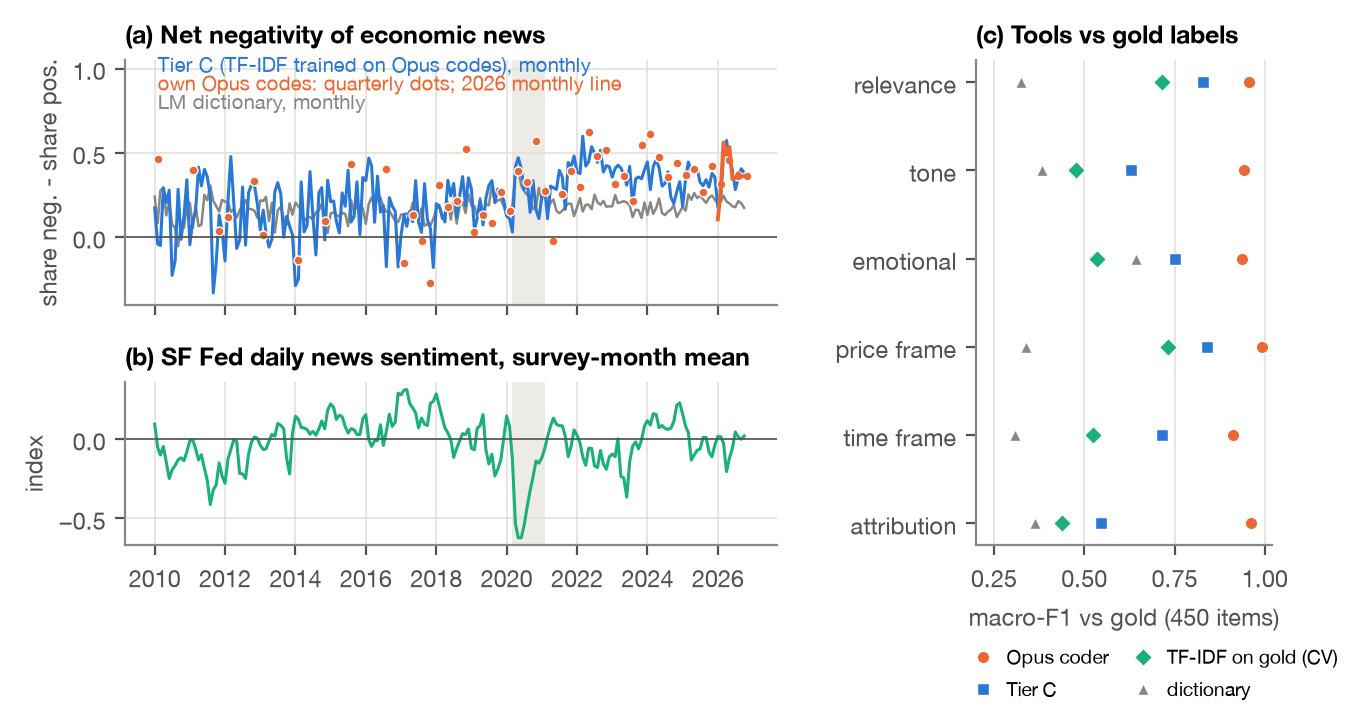

In [3]:
print(json.dumps(PREREG, indent=1)[:6000])
for t, n in PREREG_NOTES: print(t, '|', n)
display(pd.read_csv(TABLES / 'val_agreement_AB.csv').round(3))
v = pd.read_csv(TABLES / 'val_tools_vs_gold.csv')
display(v[v.subset == 'all'].pivot_table(index='field', columns='tool', values='macro_f1').round(3))
display(v[v.tool == 'opus'].pivot_table(index='field', columns='subset', values='macro_f1').round(3))
display(pd.read_csv(TABLES / 'val_per_class.csv').query("tool == 'opus'").round(3))
display(pd.read_csv(TABLES / 'val_swaps.csv').round(3))
print('test-retest kappa:', {k: round(x['kappa'], 3) for k, x in V['test_retest'].items()})
print('minimal pairs:', V['minimal_pairs'])
print(json.dumps(MED, indent=1)[:3000])
display(Image(filename=str(FIGURES / 'fig1_media.png'), width=950))

**How the measurement is validated.** The gold set is 450 items (180 national headlines, 120 local headlines, 150 Reddit posts; a third each from 2010 to 2019, 2020 to 2024 and 2025 to 2026), drawn on text features only. Two independent Claude Opus annotators (A, B) labelled it from the labelling guide alone; a third, fresh Opus instance adjudicated every item where A and B differed, seeing the two labels in random order without names. Agreement is Cohen's kappa (plus linear-weighted kappa and ordinal Krippendorff's alpha for tone, and Gwet's AC1 for skewed fields). The coder (Opus with `prompts/coder_v1.md`, items shown without date or outlet) is scored against the adjudicated gold labels by class, by source type, by period, separately on items where the annotators agreed or disagreed on that field, and on the 55 items with any disagreement. The baselines are the Loughran-McDonald dictionary with keyword rules, TF-IDF + logistic regression with 5-fold cross-validation on the gold labels, and the same classifier trained on Opus codes of non-gold items. These are LLM labels, not human labels, so agreement between Opus instances is an upper bound on reliability; the minimal-pair suite (labels known by construction), the test-retest run and the swap tests are the checks that do not lean on LLM labels.

## 4. Economic baseline and the sentiment gap

*Readings used:* Bolhuis, Cramer, Schulz and Summers (2024), the key paper for an economy-only sentiment model; Bybee et al. (2024) for using text only where it adds to macro data.

**Model E.** ICS_t = 117.2 - 4.87 U_t - 2.18 π_t + 0.87 g_t (Jan 2010 to Dec 2019, N = 120, R² = 0.88; EWC p < 0.001, 0.075, 0.036), each regressor the latest value published by day 14 of month t. The residuals are stationary (Engle-Granger p < 0.001), so this is not a spurious trend fit. In a dry run (fit 2010 to 2016, predict 2017 to 2019) the bootstrap band covered 33 of 36 months (92%).

**The gap.** Out of sample the model expects sentiment around 90 in 2026; actual sentiment was 44.8 to 56.6. The Jan to Oct 2026 mean gap is **-39.9 points**; if the 2010s relation still held, a ten-month mean this far out has probability < 0.0005 (bootstrap no-change band -5.6 to +5.2; an AR(1) check gives ±6.3). From Feb 2021 to Oct 2026 the mean gap is -27.2 and 93% of those 69 months lie outside the 95% band. Under this model the gap is unexplained pessimism, not proof of any bias.

![Figure 2](outputs/figures/fig2_baseline_gap.png)
*Figure 2. (a) Michigan ICS (black) and Model E, fit Jan 2010 to Dec 2019 on real-time data (solid blue) and predicted from Jan 2020 (dashed), with its 95% moving-block bootstrap band. (b) Gap = ICS minus Model E: grey bars in-sample residuals, orange out-of-sample gaps. Grey shading: COVID window (Mar 2020 to Jan 2021), left out by design (real-time GDP growth -33% to +33% annualised). (c) 2026 mean gap for ICS, ICC, ICE (Jan to Oct) and the five questions (relative scores, Jan to Aug, where their tables end), each from its own Model E. Panel (a) follows Bolhuis et al. (2024). Descriptive, except the bands.*

Model E (ICS):


,coef,se_ewc,p_ewc,se_nw,p_nw
const,117.2404,2.6989,0.0000,2.2271,0.0000
U,-4.8656,0.3502,0.0000,0.2919,0.0000
pi,-2.1801,1.0982,0.0752,1.1665,0.0616
g_qoq,0.8723,0.3609,0.0363,0.3774,0.0208


ICS          R2 0.881 | 2026 gap -39.9 (null band -5.6 to 5.2, p < 0.0005) | share explained 0.159 [0.054, 0.264]
ICC          R2 0.928 | 2026 gap -55.6 (null band -5.1 to 5.1, p < 0.0005) | share explained 0.116 [0.045, 0.188]
ICE          R2 0.793 | 2026 gap -29.8 (null band -6.8 to 6.5, p < 0.0005) | share explained 0.205 [0.049, 0.360]
X1_fin_now   R2 0.941 | 2026 gap -58.7 (null band -6.5 to 6.7, p < 0.0005) | share explained 0.081 [-0.016, 0.178]
X2_fin_exp   R2 0.835 | 2026 gap -43.1 (null band -6.4 to 6.3, p < 0.0005) | share explained 0.057 [-0.012, 0.127]
X3_bus_1y    R2 0.757 | 2026 gap -46.7 (null band -15.4 to 14.3, p < 0.0005) | share explained 0.273 [0.066, 0.479]
X4_bus_5y    R2 0.651 | 2026 gap -29.6 (null band -13.4 to 11.7, p < 0.0005) | share explained 0.291 [0.080, 0.502]
X5_durables  R2 0.837 | 2026 gap -85.7 (null band -10.2 to 8.5, p < 0.0005) | share explained 0.145 [0.082, 0.207]
coverage check: {'N': 36, 'boot_coverage': 0.9166666666666666, 'analytic_coverage

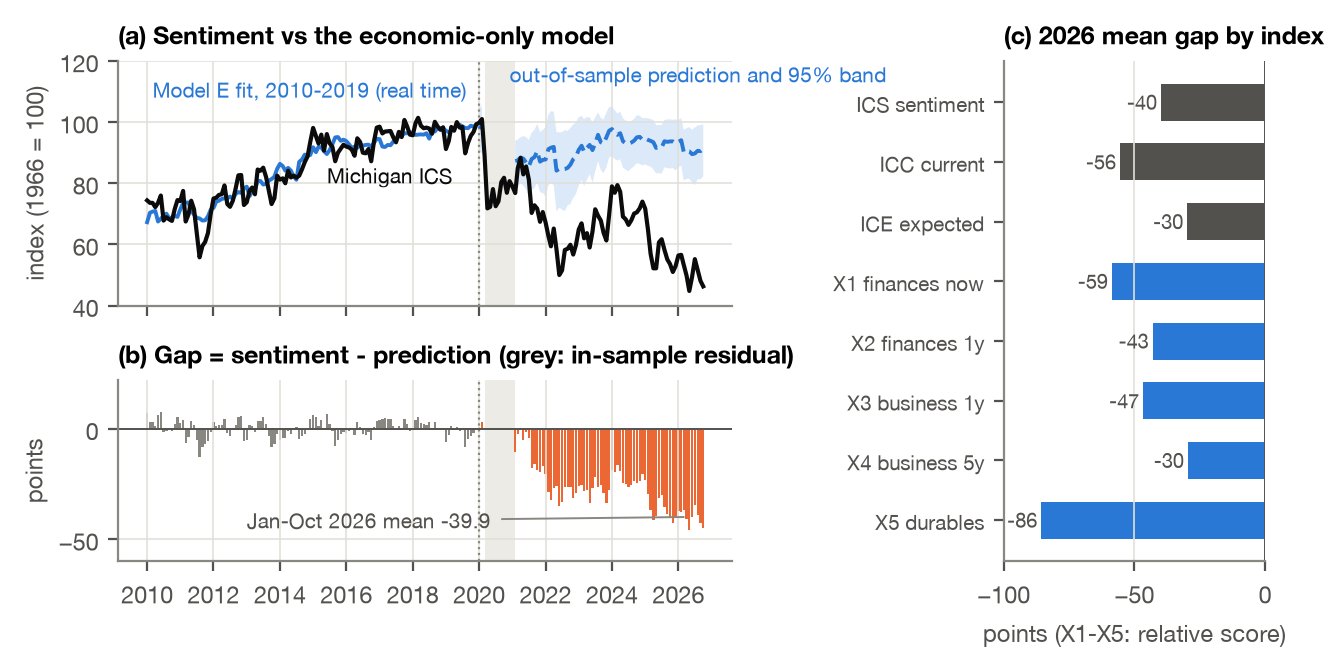

In [4]:
print('Model E (ICS):'); display(pd.DataFrame(E['E_ICS']['coef']).T.round(4))
for k in ['ICS', 'ICC', 'ICE', 'X1_fin_now', 'X2_fin_exp', 'X3_bus_1y', 'X4_bus_5y', 'X5_durables']:
    e = E[f'E_{k}']; d = e['decomposition_2019_to_2026']
    print(f"{k:12s} R2 {e['R2_train']:.3f} | 2026 gap {e['mean_gap_2026']:.1f} (null band {e['mean_gap_2026_test']['null_lo']:.1f} to {e['mean_gap_2026_test']['null_hi']:.1f}, p {e['mean_gap_2026_test']['p_text']}) | share explained {d['share_explained']:.3f} [{d['share_lo']:.3f}, {d['share_hi']:.3f}]")
print('coverage check:', E['coverage_check_2017_19'])
display(Image(filename=str(FIGURES / 'fig2_baseline_gap.png'), width=950))

**How Figure 2 is made.** For each survey month t the economic data are the values published by day 14 of t (ALFRED vintages): the latest unemployment rate, headline PCE inflation over 12 months from the same vintage, and the latest quarter's real GDP growth (QoQ SAAR from the GDPC1 vintage). Model E is an OLS fit of the index on these three over Jan 2010 to Dec 2019. Panel (a) shows the fit and, from Jan 2020, the out-of-sample prediction with a 95% moving-block bootstrap band (block 12, coefficients re-estimated). Panel (b) is the gap (index minus prediction); grey bars are in-sample residuals, orange bars out-of-sample gaps. The COVID window (Mar 2020 to Jan 2021) is excluded by design because real-time GDP growth of -33 to +33% (annualised) drives a linear prediction off scale. Panel (c) repeats the model for the current and expectations indexes and for each of Michigan's five questions (their tables end in Aug 2026). Descriptive, except the bands.

## 5. RQ1: How can we measure bias in news coverage or social media?

*Readings used:* Sacerdote, Sehgal and Cook (2020), the key paper (coverage against a benchmark, outlet groups, negativity LPM); Soroka (2006) and External: Gambetti, Maffei-Faccioli and Zoi (2023) for asymmetry; Harris and Sojourner (2024).

![Figure 3](outputs/figures/fig3_bias_tests.png)
*Figure 3. The four bias tests. (a) Monthly Tier C net negativity: its rise per 1 pp deterioration (bad news, orange) and its fall per 1 pp improvement (good news, blue) in unemployment (3-month change) and inflation (12-month change in the 12-month rate), with 90% EWC intervals; symmetric coverage puts both dots of a pair at the same height; Jan 2010 to Oct 2026 excluding the COVID window, N = 191. (b) Share of release-day headlines (Opus-coded, the day of and after each release) that are negative, by how much the released number changed from the previous month as then published (U-3 to one decimal; CPI 12-month change from the unadjusted index, rounded to one decimal as BLS publishes it); x labels give items for jobs and CPI days. (c) Among Opus-coded news items about the direction of inflation, the share saying it is rising, in months when published inflation fell vs rose (95% bootstrap CI over months for the falling side). (d) Negative share of Opus-coded news items by outlet group under Democratic vs Republican presidents (numbers: items). Panel (c) copies the logic of Sacerdote et al.'s Table 3 (rising vs falling stories in falling periods); (d) their outlet-group comparison. (a) and (b) are tests; (c) and (d) are descriptive with intervals.*

**Result.** Bias can be measured, but only one dimension at a time and only against a stated benchmark; with those benchmarks I find one clear bias (inflation coverage), no clear bias in unemployment or release-day coverage, mostly accurate numbers with loose definitions, and outlet differences that are consistent with lean but are descriptive.
1. **Negativity asymmetry.** Coverage gets more negative when inflation rises (+0.057 per pp) and does not get less negative when it falls (-0.045, wrong direction): asymmetry 0.10, one-sided p = 0.002 (p = 0.019 without 2020 to 2021). The SF Fed index shows the same pattern more weakly (p = 0.10; 0.040 without 2020 to 2021). For unemployment the bad-news response (0.30) exceeds the good-news one (0.10) but not significantly (p = 0.20; 0.47 without 2020 to 2021).
2. **Selection against benchmarks.** In the 97 months when published inflation fell, 26 of 78 inflation-direction stories (33%, 95% CI 21% to 46%) still said inflation was rising; in the 102 rising months the share is 59%. Layoff stories are 53% of layoff-or-hiring coverage on average while JOLTS layoffs are 25% of layoffs plus hires, and the two do not move together (r = -0.11). "Prices high" salience fits the inflation rate (R² 0.35) better than the price level against trend (0.27).
3. **Release days and calibration.** Jobs-day negativity is 0.24 to 0.28 when unemployment fell or held, 0.37 after a +0.1 rise and 0.56 after +0.2 or more; the +0.1 and -0.1 bins are not asymmetric (sum 0.10, p = 0.35; 433 items, 187 releases), and CPI days show no asymmetry (p = 0.15). Changes within CPS sampling error (|ΔU| ≤ 0.1) get emotional wording in 10% of items, the same as larger changes (10%). Of 161 numerical claims, 83% match the official value published that day under the pre-registered tolerance (±0.1 pp, payrolls ±1k; CPI as BLS publishes it, from the unadjusted index): payrolls 87% (69), unemployment 90% (50), inflation 65% (40); allowing for rounding ("3%" for 3.2%) gives 86%. Only 10% of claims name the measure (CPI, PCE, core).
4. **Attribution and outlet groups.** Relative to center outlets, right-leaning outlets are 9.7 points more likely to be negative (LPM with month effects, p = 0.001) and Reddit 10.5 points (p < 0.001); left-leaning and local outlets do not differ (p = 0.70, 0.95). Right-leaning negativity is 64% under Democratic presidents and 57% under Republican ones; left and center hardly move (47% to 48%), local rises from 46% to 54%. Blame on the president (difference in differences, right minus left, Democratic minus Republican president) is +0.03 (95% CI -0.07 to +0.07): no partisan asymmetry detected, on only three changes of president.
5. **Framing (descriptive).** Price stories are framed as price levels more than rates in every group (52% of price-framed center items, 79% to 90% for the other news groups); the level share was 71% to 100% a year before 2020 and fell to 66% to 67% in 2021 to 2023, when inflation-rate stories took over. Household framing rose from 9% to 19% of items a year before 2020 to 31% to 33% in 2022 to 2024. Right-leaning outlets use emotional wording most (33% of items vs 13% to 14% for the other news groups; Reddit 25%).

*Against Sacerdote et al. (2020):* they find US major-outlet COVID stories 91% negative (unadjusted) and rising-case stories outnumbering falling-case stories 5.3 to 1 even when cases fell. My inflation ratio in falling months is 0.5 to 1 (26 up vs 52 down), so economic coverage does report improvement, just less than it reports deterioration, and the asymmetry shows up in tone rather than in what stories exist. Like them, I find small differences between left and center outlets; unlike them, right-leaning outlets here are more negative.

*Why this result:* inflation is the dimension where "good news" is ambiguous: a lower inflation rate still means higher prices, so a story about cooling inflation is often written around prices still being high, which the coder rightly marks negative. For unemployment, Gambetti et al. (2023) show apparent negativity bias can come from unemployment itself rising faster than it falls; my unemployment result is consistent with that. Inflation claims fail calibration most often (14 of 40) because headlines mix CPI and PCE, month and year changes without saying which, which is a definition problem more than a false number.

**In short.** Measured against benchmarks, news coverage over-weights rising inflation and under-reports cooling, but it gets most jobs numbers right and shows no detectable asymmetry for job news (bad 0.30 vs good 0.10 per pp, p = 0.20, which is not the same as proven symmetry). That is a selective-framing finding about inflation, not evidence of a general negativity bias.

{
 "TC_NEGNET|all": {
  "N": 191,
  "nu": 13,
  "R2": 0.11849357285004347,
  "U": {
   "resp_bad": 0.3032085046995856,
   "resp_good": 0.1022210450713729,
   "se_bad": 0.15699462582802515,
   "se_good": 0.10437856671952485,
   "asym": 0.20098745962821268,
   "se_asym": 0.23403009120326665,
   "t": 0.8588103290257884,
   "p_one_sided": 0.20300124106388218,
   "ci90": [
    -0.21346424454950585,
    0.6154391638059312
   ]
  },
  "pi": {
   "resp_bad": 0.056691296412838696,
   "resp_good": -0.04452475484374134,
   "se_bad": 0.025135863044262883,
   "se_good": 0.015383368468321095,
   "asym": 0.10121605125658004,
   "se_asym": 0.028914758881168262,
   "t": 3.5004978486090885,
   "p_one_sided": 0.001955155676857445,
   "ci90": [
    0.05000993911701114,
    0.15242216339614895
   ]
  }
 },
 "TC_NEGNET|ex_2020_21": {
  "N": 180,
  "nu": 13,
  "R2": 0.1287873720596593,
  "U": {
   "resp_bad": 0.23255189162088247,
   "resp_good": 0.21133851278522664,
   "se_bad": 0.16373353601367854,
   "se_g

,release,bin,items,releases,neg,pos,emo
0,cpi,<=-0.2,80,47,0.300,0.312,0.075
1,cpi,-0.1,50,21,0.340,0.280,0.100
2,cpi,0,45,18,0.467,0.133,0.089
3,cpi,+0.1,34,18,0.324,0.206,0.029
4,cpi,>=+0.2,104,54,0.529,0.115,0.163
5,jobs,<=-0.2,98,47,0.276,0.520,0.071
6,jobs,-0.1,97,43,0.237,0.464,0.062
7,jobs,0,114,48,0.254,0.482,0.123
8,jobs,+0.1,92,36,0.370,0.370,0.120
9,jobs,>=+0.2,32,13,0.562,0.156,0.188


{
 "jobs": {
  "neg_shift_bad_0.1": 0.11517925247902364,
  "neg_shift_good_0.1": -0.01727256285042652,
  "asym_sum": 0.09790668962859711,
  "p_two_sided": 0.34667525278199207,
  "N_items": 433,
  "releases": 187
 },
 "jobs_noise_band": {
  "emotional_small_changes": 0.10231023102310231,
  "emotional_large_changes": 0.1,
  "n_small": 303,
  "n_large": 130
 },
 "cpi": {
  "neg_shift_bad_0.1": -0.14313725490196097,
  "neg_shift_good_0.1": -0.12666666666666657,
  "asym_sum": -0.26980392156862754,
  "p_two_sided": 0.14911948859564617,
  "N_items": 313,
  "releases": 158
 }
}
{
 "claims": 161,
 "match_rate": 0.8260869565217391,
 "match_rate_rounding_rule": 0.8571428571428571,
 "by_indicator_rounding_rule": {
  "gdp_growth": {
   "mean": 1.0,
   "size": 2
  },
  "inflation": {
   "mean": 0.65,
   "size": 40
  },
  "payrolls": {
   "mean": 0.942,
   "size": 69
  },
  "unemployment_rate": {
   "mean": 0.9,
   "size": 50
  }
 },
 "by_indicator": {
  "gdp_growth": {
   "mean": 1.0,
   "size": 2
 

BLAME_PRES                      CREDIT_PRES                      ATTR_ANY                     
group     center   left  local  right      center   left  local  right   center   left  local  right
pres                                                                                                
D          0.022  0.008  0.012  0.054       0.007  0.022  0.004  0.015    0.113  0.095  0.083  0.112
R          0.040  0.044  0.049  0.058       0.025  0.029  0.034  0.081    0.158  0.197  0.172  0.310

,neg,pos,NEGNET,EMO,LEVEL,HH,FC,N1,N2,N3,N4
group,,,,,,,,,,,
center,0.484,0.204,0.280,0.137,0.519,0.104,0.271,0.109,0.055,0.116,0.094
left,0.476,0.172,0.304,0.137,0.795,0.211,0.220,0.191,0.036,0.131,0.083
local,0.504,0.272,0.231,0.127,0.898,0.256,0.210,0.210,0.023,0.166,0.161
reddit,0.601,0.099,0.502,0.252,0.682,0.227,0.226,0.148,0.016,0.157,0.047
right,0.602,0.179,0.423,0.328,0.855,0.249,0.202,0.285,0.049,0.171,0.070


{
 "D|center": {
  "neg_share": 0.48363636363636364,
  "n": 275
 },
 "D|left": {
  "neg_share": 0.4720670391061452,
  "n": 358
 },
 "D|local": {
  "neg_share": 0.4583333333333333,
  "n": 240
 },
 "D|right": {
  "neg_share": 0.6439024390243903,
  "n": 205
 },
 "R|center": {
  "neg_share": 0.484472049689441,
  "n": 322
 },
 "R|left": {
  "neg_share": 0.4793187347931874,
  "n": 411
 },
 "R|local": {
  "neg_share": 0.5368098159509203,
  "n": 326
 },
 "R|right": {
  "neg_share": 0.5741935483870968,
  "n": 310
 }
}
{
 "left": {
  "coef": -0.010777437324673822,
  "p": 0.6973438470067871
 },
 "local": {
  "coef": 0.0018132896750690242,
  "p": 0.9521836458067926
 },
 "reddit": {
  "coef": 0.10493007155338847,
  "p": 0.00028231946300217664
 },
 "right": {
  "coef": 0.09725101191275153,
  "p": 0.0014073243071947383
 }
}


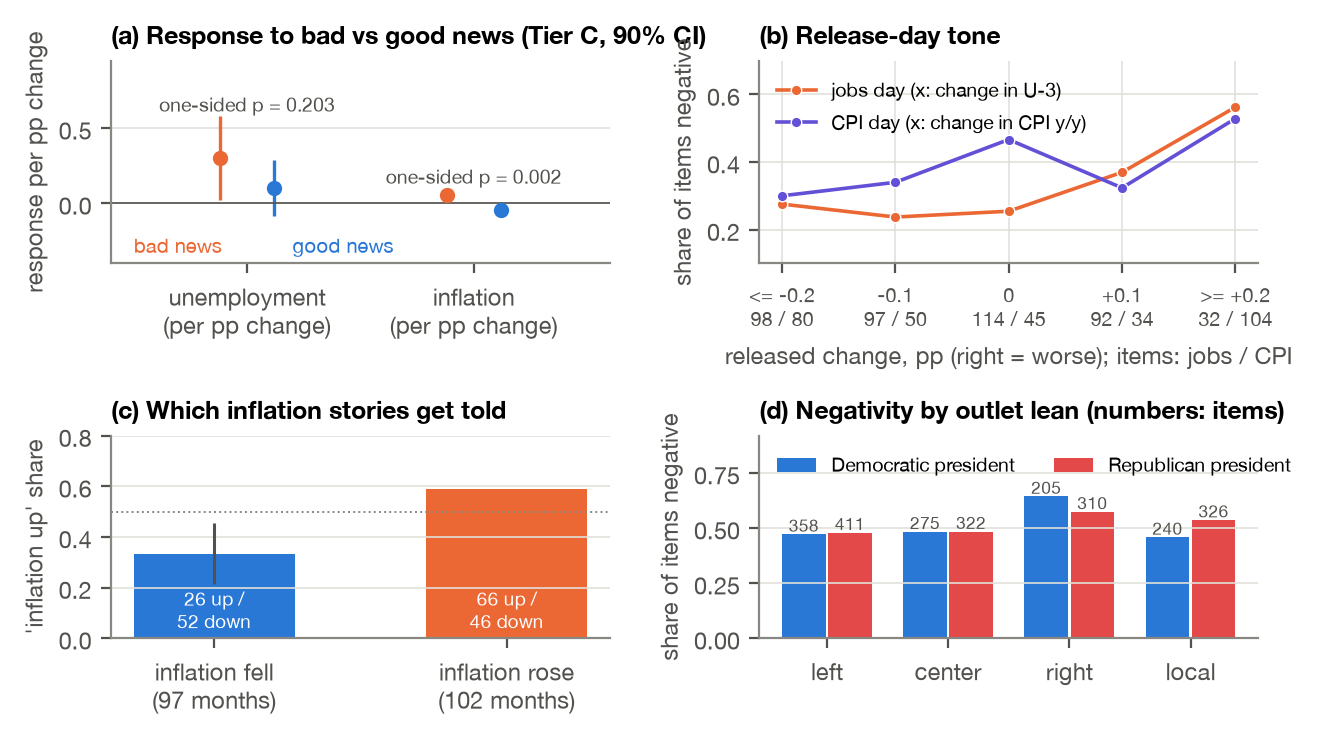

In [5]:
print(json.dumps(R['rq1']['asymmetry'], indent=1)[:4000])
print(json.dumps(R['rq1']['selection'], indent=1))
display(pd.read_csv(TABLES / 'rq1_release_bins.csv').round(3))
print(json.dumps(R['rq1']['release_days'], indent=1)); print(json.dumps(R['rq1']['calibration'], indent=1))
display(pd.read_csv(TABLES / 'rq1_attribution.csv', header=[0, 1], index_col=0).round(3))
display(pd.read_csv(TABLES / 'rq1_by_source_group.csv', index_col=0).round(3))
print(json.dumps(R['rq1']['neg_by_lean_and_president'], indent=1)); print(json.dumps(R['rq1']['lpm_negative_by_group'], indent=1))
display(Image(filename=str(FIGURES / 'fig3_bias_tests.png'), width=950))

**How the bias measures are computed.** Item-level tests (selection, release days, calibration, attribution, groups) use only headlines the Opus coder judged relevant; the monthly Tier C series uses the relevance and tone of the TF-IDF classifier trained on Opus codes. A survey month's media window is the 15th of the previous month to the 14th, so it ends at the prediction date. Monthly news measures are the mean over four outlet groups (left-leaning national, center national, right-leaning national, local) of each group's share, with fixed equal weights, so nothing is estimated on later data. Tone = share negative minus share positive. The asymmetry test regresses monthly tone on the rise and the fall of unemployment (3-month change) and of inflation (12-month change in the 12-month rate) separately; the response to a deterioration is the coefficient on the rise, the response to an improvement minus the coefficient on the fall, and negativity bias means the first is larger (one-sided test). Release-day coverage is tone of headlines published on the day of and the day after each jobs or CPI release, grouped by how much the released number changed. Calibration compares each numerical claim with the official value in the data vintage of the publication date.

## 6. RQ2: How can we determine the impact of such bias on Michigan sentiment?

*Readings used:* Shapiro, Sudhof and Wilson (2022), the key paper (news sentiment and Michigan); Souza et al. (2015) for Granger tests both ways; Doms and Morin (2004); External: Toda and Yamamoto (1995), Cinelli and Hazlett (2020), Gentzkow and Shapiro (2010) for demand as an analogy. Figure: Figure 1(a, b) shows the media series used.

**Result.** With 17 years of monthly data I cannot detect a depressing effect of media negativity on sentiment that survives the pre-registered rule, and the most the association could explain, even if fully causal, is small next to the gap. This is a statement about what is detectable, not proof that media do not matter.
- **Direct level model** (ICS on the economy, the six household controls and media, N = 191, EWC ν = 13). Tier C negativity: -6.17 (SE 5.05), one-sided p = 0.12, BH q = 0.18. Implied contribution if causal: Tier C negativity rose 0.16 from 2019 to 2026, so -1.0 point of the -39.9 gap (90% CI -2.4 to +0.4). Robustness value 0.12: a confounder explaining 12% of the residual variance of both would remove it. The claim rule fails: expected sign and permutation p (0.096) pass, but BH q, the household controls, leave-one-year-out (max p 0.44) and dropping 2021 to 2022 (p 0.47) do not. In changes (differenced on the full monthly index, both months outside the COVID window) the coefficient has the wrong sign (+0.22, p = 0.89).
- **SF Fed.** Coefficient +22.4 (expected sign, q = 0.010, survives leave-one-year-out and dropping 2021 to 2022), but the index barely changed between 2019 and 2026 (+0.03), so its implied contribution is +0.6 points, the opposite direction to the gap. It also holds in changes (+12.9, p = 0.004).
- **The original measure at its fallback frequency.** Own-Opus quarterly negativity (N = 47 quarters): -23.8 with economy only (p = 0.050), +0.44 once household controls enter (p = 0.96).
- **Out-of-sample errors.** The economy-only nowcast errors of 2017 to 2026 correlate -0.58 with real-time Tier C negativity (p = 0.003, N = 107; -0.51 with the full-sample series; minimum detectable r 0.47 with effective N 33), so months with darker coverage are months with darker sentiment than the economy predicts. Both series trend after 2021, and the in-sample level model above loses the link once household controls enter.
- **Direction (Toda-Yamamoto, circular-shift permutation, BH).** Tier C to sentiment: p = 0.057 (permutation 0.096, q = 0.115); sentiment to Tier C: p = 0.67. SF Fed to sentiment: p = 0.80; **sentiment to SF Fed: p = 0.0005 (permutation 0.006, q = 0.003)**.
- **Reverse causality and demand.** Within sub-month cells, negative Reddit posts score 0.86 log points higher than others (p = 0.003, N = 616), consistent with audiences rewarding negative content.
- **Party timing.** Around the 2024 election Democrats fell 21.8 and Republicans rose 31.8 points from October to December while unemployment moved +0.1 and inflation +0.07; right-leaning outlets' Tier C net negativity went from 0.42 to 0.34 (Aug to Oct vs Nov to Jan, 72 and 74 items; 3-month windows because single months are too thin, a dated change) and left-leaning from 0.22 to 0.27. The 2020 right-leaning cells (15 and 9 items) are too small to test.

*Against Shapiro et al. (2022):* they find news sentiment predicts Michigan sentiment in and out of sample (index-ICS correlation 0.58, 0.74 after 2005). I find the same kind of association out of sample (r = -0.58 with the nowcast errors) and their own index stays significant with my controls, but its Granger direction runs from sentiment to news over my sample, and for Tier C the link does not survive household-pressure controls.

*Why this result:* three things push the estimate around: common shocks (gas prices and tariffs move both coverage and sentiment), reverse causality (sentiment leads the SF Fed index and negative posts get more engagement) and measurement noise in monthly tone (Tier C tone F1 0.63), which biases toward zero. For Tier C the household controls absorb most of the association, which is what you expect if coverage mostly reports the same pressures consumers feel; the SF Fed link survives them, but that index moved too little since 2019 to account for the gap, and sentiment leads it.

**How a causal answer would be obtained (the design I propose; brief section 4).** A pre-registered randomized framing experiment, IRB approval first, consenting adult US panel (for example Prolific or a probability panel such as NORC AmeriSpeak), about 4,000 respondents. Arms, all truthful and built from the same official numbers: (1) neutral factual summary of the latest CPI, jobs and GDP release; (2) price-level framing ("prices are 25% higher than in 2020"); (3) rate framing ("inflation slowed to 3%"); (4) household framing with a typical-family example; (5) a pure control with no economic text. Outcomes: Michigan's five questions verbatim, scored as in the index, plus inflation expectations and a recall item; pre-treatment party, income and news diet as moderators; attention checks; a two-week follow-up for decay. With 800 per arm and an assumed residual SD of 25 index points (to be checked in a pilot) the design detects a 3.5-point difference between two arms (80% power, 5% level); detecting 2.4 points, the upper bound on the media contribution above, needs about 1,700 per arm. Even a clean effect on this sample does not give an effect on the national index. Transporting it needs: (a) exposure estimates, the share of Michigan's population that actually meets each frame and how often, from a panel with tracked news exposure or from Michigan's news-heard items extended to frames; (b) representative sampling or post-stratification of the experiment to Michigan's margins (age, income, region, education, party); (c) effect homogeneity within those cells, or modelled heterogeneity; (d) consistency between a one-shot vignette and months of repeated exposure, with the follow-up measuring decay; (e) no interference (SUTVA) through shared conversation. National effect ≈ Σ over cells of (cell share) × (exposure rate) × (cell effect), with each assumption stated and tested where possible. Quasi-experiments (local paper closures such as the 2026 Post-Gazette sale; regional coverage vs regional sentiment) are possible but local cells are thin.

**In short.** News tone and sentiment are associated (most robustly for the SF Fed index), but taken as causal the link explains about 1 point of the 40-point gap for Tier C and the wrong direction for SF Fed; for Tier C it does not survive household controls, and the SF Fed index follows sentiment rather than leading it. Measuring the impact properly needs randomized framing plus exposure data, and I set out that design.

In [6]:
display(pd.read_csv(TABLES / 'rq2_family.csv').round(4))
display(pd.read_csv(TABLES / 'rq2_toda_yamamoto.csv').round(4))
print('claim rule (Tier C):', R['rq2']['claim_rule_TC_NEGNET']); print('MDE:', R['rq2']['mde'])
print('own-Opus quarterly (the original measure at its fallback frequency):', R['rq2']['quarterly_own_opus'])
print({k: v for k, v in R['rq2'].items() if k.startswith('oos_gap') or k == 'reddit_demand'})
print(json.dumps(R['rq2']['party_timing'], indent=1)[:3000])

,test,media,N,nu,coef,se,p_two_sided,p_expected_sign,expected_sign,implied_contribution_if_causal,implied_ci90,media_change_2019_2026,robustness_value,loyo_min_coef,loyo_max_coef,loyo_max_p,drop_2021_22_coef,drop_2021_22_p,bh_q
0,level: S on econ + H1 + TC_NEGNET,TC_NEGNET,191,13.0,-6.1719,5.0460,0.2430,0.1215,-1,-0.9877,"[np.float64(-2.4177566515991247), np.float64(0.442366199125395)]",0.1600,0.1193,-8.7963,-3.2207,0.4361,-2.9169,0.4662,0.1822
1,"changes: dS on dU, dpi, dg, dTC_NEGNET",TC_NEGNET,189,NaN,0.2147,NaN,0.8860,0.5570,-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,level: S on econ + H1 + SFFED,SFFED,191,13.0,22.4286,6.9805,0.0068,0.0034,1,0.6234,"[np.float64(0.27982051818907566), np.float64(0.9670776920836387)]",0.0278,0.2908,17.6816,27.3003,0.0192,29.0124,0.0004,0.0102
3,"changes: dS on dU, dpi, dg, dSFFED",SFFED,189,NaN,12.9017,NaN,0.0038,0.0019,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,test,lag_p,N,wald,p,sum_coef,p_perm,n_shifts,bh_q
0,TY: TC_NEGNET -> S,1,187,3.6084,0.0575,-3.1775,0.0964,165,0.1150
1,TY: S -> TC_NEGNET,1,187,0.1832,0.6687,-0.0014,0.6687,165,0.8024
2,TY: SFFED -> S,1,187,0.0610,0.8049,-0.9787,0.8373,165,0.8049
3,TY: S -> SFFED,2,185,15.3269,0.0005,0.0018,0.0060,165,0.0028


claim rule (Tier C): {'expected_sign': True, 'bh_q_lt_0.10': False, 'permutation_p_lt_0.10': True, 'survives_h1_controls': False, 'survives_loyo': False, 'survives_drop_2021_22': False, 'passes': False}
MDE: {'N': 107, 'rho_x': 0.902282406040841, 'rho_y': 0.5822944268430549, 'N_eff': 33.291621501420515, 'mde_r': 0.46918834443684565}
own-Opus quarterly (the original measure at its fallback frequency): {'N_quarters': 47, 'nu': 5, 'coef_with_H1': 0.4383866351110868, 'p_with_H1': 0.9562905767603889, 'coef_econ_only': -23.847095868944812, 'p_econ_only': 0.05036977121354802}
{'oos_gap_on_own_rt': {'N': 107, 'coef': -43.90155000203262, 'p': 0.003372488140564789, 'r': -0.5784972347945456}, 'oos_gap_on_own': {'N': 107, 'coef': -37.2421805892688, 'p': 0.005565810059245058, 'r': -0.5093927169253281}, 'oos_gap_on_sf': {'N': 107, 'coef': 25.756168828713207, 'p': 0.13681917756568573, 'r': 0.336740914178658}, 'reddit_demand': {'N': 616, 'coef_neg_log_score': 0.8610370504866036, 'p': 0.003432405342976

## 7. RQ3: How much of the gap can unemployment, inflation and real GDP growth explain?

*Readings used:* Bolhuis et al. (2024), the key paper; External: Stantcheva (2024) on why people dislike inflation (buying power); Malmendier and Nagel (2016) on experience effects. Figure: Figure 2(c).

**Result.** Very little: about a sixth. From the 2019 average (ICS 96.0) to Jan to Oct 2026 (51.2) sentiment fell 44.8 points; the three conditions moved +0.56 pp (unemployment), +1.82 pp (inflation) and -0.51 pp (growth), which Model E turns into a predicted fall of 7.1 points: **16% of the actual fall (95% CI 5% to 26%; bootstrap 9% to 23%)**. Inflation accounts for 4.0 points, unemployment 2.7, growth 0.4. Current conditions: 12% explained; expectations: 20%.
- **The gap sits in households' own finances and buying conditions.** The 2026 gap is largest for durables buying conditions (X5, -86 relative points) and current personal finances (X1, -59), smallest for business conditions over five years (X4, -30); Model E explains 6% of the fall in X2, 8% in X1 and 14% in X5 but 27% to 29% in X3 and X4.
- **Robust to how the economy is measured.** YoY GDP (-40.8), core PCE (-40.0), CPI (-41.7), start-of-month information (-39.7), revised instead of real-time data (-41.0) and a quarterly model (-40.3, Q1 to Q3) all give the same gap.
- **Household-pressure controls do not close it.** In the 2010 to 2019 sample, adding 36-month inflation, real income growth, the mortgage rate, affordability, U-6 minus U-3 and the debt-service ratio, alone or together, leaves the 2026 gap between -39.9 and -43.8 (all six jointly: EWC p = 0.46, gap -43.2). In a long real-time sample (1992 to 2019, N = 336, CPI-based), 36-month inflation, mortgage rate and affordability together close 6% (jointly p < 0.001), because the mortgage rate enters with a positive sign (+1.7 alone): high rates came with booms historically.
- **Seasonality** is present in training (month dummies, Newey-West p < 0.001; Newey and West 1987) but does not change the gap's size.

*Against Bolhuis et al. (2024):* their 1978 to 2019 model leaves a 2.1 SD gap in 2023, similar in kind to mine, and an inflation measure that includes borrowing costs closes almost three quarters of it. My mortgage-rate and affordability controls do not, because in history high rates went with good times; their result needs their cost-of-money price index, which I did not build (a limitation).

*Why this result:* a linear model learns how sentiment moved with the *rate* of inflation in a decade when the price *level* never jumped. The PCE price level was about 14 log points (roughly 15%) above its 2010 to 2019 trend on average in 2026, and a lower inflation rate leaves that level in place, so falling inflation does not undo the higher bill: in Aug 2026, 53% of respondents said they were worse off because of higher prices, against 6% to 9% in 2019. Aggregate growth also differs from household experience: GDP grew while real disposable income per head grew between -1.4% and +1.4% a year in 2026 and the 30-year mortgage rate rose from 6.2% to 7.4%.

**In short.** Unemployment, inflation and growth explain about a sixth of the fall in sentiment since 2019; the rest sits in personal finances and buying conditions, which points at price levels and borrowing costs that a 2010s model cannot price.

In [7]:
display(pd.read_csv(TABLES / 'rq3_h1_controls_2010_19.csv').round(3))
display(pd.read_csv(TABLES / 'rq3_h1_controls_long.csv').round(3))
print(json.dumps(E['variants'], indent=1)); print('revision effect share:', E['h3_revision_effect_share'])
print('seasonality:', E['seasonality']); print('rolling sign changes:', E['rolling_sign_changes'], E['expanding_vs_fixed_rmse_post'])
display(pd.read_csv(TABLES / 'rq3_group_gaps.csv', index_col=0).round(2))

,controls,R2_train,mean_gap_2026,share_2026_gap_closed,mean_gap_post,wald_F_ewc,wald_p_ewc,wald_p_nw,coef,bh_q_ewc
0,pi36,0.881,-40.595,-0.018,-28.238,0.052,0.825,0.810,{'pi36': 0.1827},0.825
1,rdpi_yoy,0.881,-39.926,-0.001,-27.196,0.188,0.674,0.668,{'rdpi_yoy': -0.1781},0.809
2,mort30,0.883,-43.424,-0.089,-29.534,1.775,0.212,0.140,{'mort30': 1.5601},0.622
3,afford,0.883,-43.835,-0.099,-30.566,1.139,0.311,0.235,{'afford': 0.0815},0.622
4,U6_gap,0.883,-40.074,-0.005,-27.437,0.657,0.437,0.324,{'U6_gap': -1.7797},0.655
5,dsr,0.889,-42.557,-0.067,-26.803,5.029,0.049,0.005,{'dsr': 2.5408},0.293
6,pi36+rdpi_yoy+mort30+afford+U6_gap+dsr,0.893,-43.168,-0.082,-23.992,1.111,0.464,0.002,"{'pi36': 0.3205, 'rdpi_yoy': -0.3757, 'mort30': 3.4876, 'afford': -0.2201, '...",NaN


,controls,N_train,nu,R2_train,mean_gap_2026,share_2026_gap_closed,mean_gap_post,n_post,wald_p_ewc,wald_p_nw,coef
0,base,336,19,0.700,-41.013,0.000,-26.149,68,NaN,NaN,"{'U': -5.2398, 'pi_cpi': -3.259, 'g_qoq': 2.2667}"
1,pi36_cpi,336,19,0.701,-40.871,0.003,-25.709,68,0.662,0.635,"{'U': -5.2124, 'pi_cpi': -3.0568, 'g_qoq': 2.2516, 'pi36_cpi': -0.1509}"
2,mort30,336,19,0.739,-41.028,-0.000,-23.790,68,0.002,0.000,"{'U': -5.094, 'pi_cpi': -4.1972, 'g_qoq': 2.0751, 'mort30': 1.71}"
3,afford,336,19,0.700,-41.087,-0.002,-26.088,68,0.816,0.793,"{'U': -5.2146, 'pi_cpi': -3.3363, 'g_qoq': 2.2633, 'afford': 0.0075}"
4,pi36_cpi+mort30+afford,336,19,0.805,-38.454,0.062,-17.757,68,0.001,0.000,"{'U': -5.1553, 'pi_cpi': -2.5851, 'g_qoq': 1.714, 'pi36_cpi': -1.1739, 'mort..."


{
 "g_yoy": {
  "R2_train": 0.870986767034562,
  "mean_gap_2026": -40.846584729541426,
  "mean_gap_post": -27.580920172276272
 },
 "core_pce": {
  "R2_train": 0.8718632129072447,
  "mean_gap_2026": -40.01908285595501,
  "mean_gap_post": -27.014871771956553
 },
 "cpi": {
  "R2_train": 0.8810453624087838,
  "mean_gap_2026": -41.68616955993323,
  "mean_gap_post": -27.99738897509569
 },
 "start_of_month_info": {
  "R2_train": 0.8749959456604248,
  "mean_gap_2026": -39.74128480056474,
  "mean_gap_post": -27.014315382773272
 },
 "revised_data": {
  "R2_train": 0.873080788403527,
  "mean_gap_2026": -41.00904571192683,
  "mean_gap_post": -28.01454669823733
 },
 "quarterly": {
  "N_train": 40,
  "R2_train": 0.9185046452692541,
  "mean_gap_2026_Q1_Q3": -40.30169971934177
 }
}
revision effect share: 0.02805631413390806
seasonality: {'p_nw_month_dummies': 0.0007284320165904523, 'note': '11 restrictions > nu, EWC F undefined'}
rolling sign changes: {'U': 2, 'pi': 2, 'g_qoq': 6} {'expanding': 16.616

,R2_train,mean_gap_2026_jan_aug
ICS_bottom,0.81,-38.35
ICS_middle,0.84,-41.57
ICS_top,0.81,-36.62
ICS_age18_34,0.72,-38.41
ICS_age35_54,0.84,-45.12
ICS_age55p,0.83,-38.04
ICS_NE,0.77,-32.78
ICS_MW,0.83,-38.78
ICS_S,0.87,-40.56
ICS_W,0.77,-41.10


## 8. RQ4: Which perceptual mechanisms can the data actually measure?

*Readings used:* Soroka (2006); External: D'Acunto, Malmendier, Ospina and Weber (2021) on salient prices; Malmendier and Nagel (2016); Carroll (2003) on news and expectations; Mian, Sufi and Khoshkhou (2023) on partisan expectations. These mechanism tests were planned before testing but are not in the timestamped pre-registration, so they are exploratory.

![Figure 4](outputs/figures/fig4_mechanisms.png)
*Figure 4. (a) Michigan's share of respondents worse off because of higher prices (Michigan Table 7) against the PCE price level relative to its 2010 to 2019 log-linear trend (log points, lagged two months to match publication), by period, COVID window dropped. (b) Recall of unfavourable news about high prices (Michigan Table 24) and the Tier C "prices high" share of coverage, each as a z-score over 2010 to 2026 (indexed to a common base instead of two axes). (c) ICS by party (Michigan Table 5b); dotted lines: 2016, 2020, 2024 elections. No class paper has this figure. Descriptive; the R² and correlations in the panels are the fits reported in the text.*

**Result.** Four mechanisms are measurable with these data (negativity bias in coverage and in the public, price-level anchoring, partisan switching), two only partly (demand for negativity, availability), experience effects only weakly, and individual-level confirmation or availability bias not at all. Text can show framing and selection; a reader's bias needs exposure, recall, belief or experimental evidence, which only the survey side partly gives.

**Table 6. Mechanisms: measure, data, result, verdict.**

| Mechanism | Measure and data | Result | Verdict |
|---|---|---|---|
| Negativity bias, supply | Coverage asymmetry (Figure 3a) | Inflation yes (p = 0.002); unemployment no (p = 0.20) | Measurable |
| Negativity bias, public | Same regression for ICS (Soroka's public side) | Inflation: a 1 pp rise lowers ICS 6.2 points, a 1 pp fall does not raise it (-2.9), p = 0.018; unemployment p = 0.11 | Measurable |
| Negativity bias, demand | Reddit score on negative tone; recalled news (Table 23) asymmetry | Negative posts +0.86 log points (p = 0.003); recalled news asymmetric for inflation (p = 0.038) | Partly (engagement is not exposure) |
| Availability / salience | Recall of price news (Table 24) vs coverage salience; gas prices beyond PCE | r = 0.78 in levels, 0.39 in changes; but recall leads coverage (TY p = 0.0001) and coverage does not lead recall (p = 0.43); gas adds nothing to Model E (p = 0.22) | Partly |
| Anchoring to past prices | Michigan Table 7 and durables "prices high" vs inflation rate vs 36-month inflation vs price level against trend | Worse off because of prices: R² 0.41 (rate), 0.66 (36-month), **0.81 (level)**; durables prices high: 0.67, 0.68, 0.77. Levels 7% (2019), 40% (2022), 51% (2026) | Measurable, consistent with level anchoring |
| Confirmation / partisan filter | Party sentiment around elections with fundamentals flat; outlet tone by lean | 2024: Democrats -21.8, Republicans +31.8 in two months; outlet tone moves less than 0.08 | Partisan switching measurable; confirmation bias of individuals not |
| Experience effects | Gap by age (Table 3n) | 18 to 34: -38.4; 35 to 54: -45.1; 55+: -38.0 | Weak, not monotonic |
| Not measurable | Which stories a respondent saw and believed; individual-level availability or confirmation bias | No exposure data link news to Michigan respondents | Needs the experiment or a panel |

*Against Soroka (2006):* he finds asymmetry on both sides in UK data, coverage and the public. I find the same for inflation in the US, and on neither side for unemployment.

*Why this result:* the price level enters people's lives through every bill, so a level that stays high keeps "worse off because of prices" high even as inflation cools, which the R² ranking shows (partly a contrast between regimes, since the level gap is near zero by construction in 2010 to 2019). Coverage behaves the other way: "prices high" salience in the news fits the inflation rate (R² 0.35) better than the level (0.27), so the media move on when inflation cools while households do not, which is hard to square with coverage creating the level anchor. The availability result points the other way from a media story: people report hearing about high prices before coverage of high prices rises, consistent with experience at the till driving both.

**In short.** The data can measure negativity asymmetry, price-level anchoring and partisan switching, and they all point to prices and party more than to coverage; whether any reader's beliefs were bent by what they read cannot be measured from text.

{
 "recall_asymmetry": {
  "N": 189,
  "nu": 13,
  "R2": 0.17112335460044836,
  "U": {
   "resp_bad": 56.76375461652769,
   "resp_good": 30.043595921619897,
   "se_bad": 29.75760932994162,
   "se_good": 22.43843043277023,
   "asym": 26.720158694907795,
   "se_asym": 43.36786182025649,
   "t": 0.6161281090050698,
   "p_one_sided": 0.2742234973632006,
   "ci90": [
    -50.08143611512848,
    103.52175350494407
   ]
  },
  "pi": {
   "resp_bad": 12.835161859642941,
   "resp_good": -3.321929912006284,
   "se_bad": 3.6845357230401286,
   "se_good": 5.870591948668906,
   "asym": 16.157091771649224,
   "se_asym": 8.392244570946893,
   "t": 1.925240814308898,
   "p_one_sided": 0.03817921862674167,
   "ci90": [
    1.2949855936698462,
    31.0191979496286
   ]
  }
 },
 "availability_recall_vs_media": {
  "N": 189,
  "corr_levels": 0.7799786232081545,
  "corr_changes": 0.3891844553142988,
  "ty_media_to_recall": {
   "lag_p": 1,
   "N": 185,
   "wald": 0.635830898379256,
   "p": 0.42522453376764

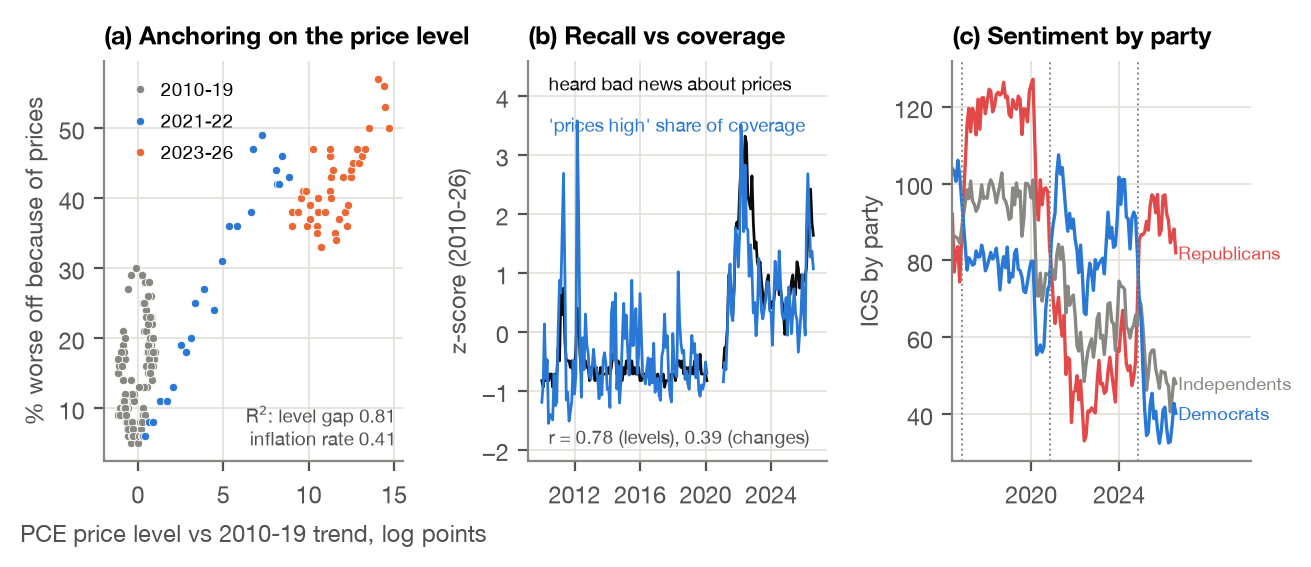

In [8]:
print(json.dumps(R['rq4'], indent=1)[:5000])
display(Image(filename=str(FIGURES / 'fig4_mechanisms.png'), width=950))

## 9. RQ5: Does media analysis improve predictions of consumer sentiment beyond economic indicators?

*Readings used:* Shapiro, Sudhof and Wilson (2022), the key paper; Bybee et al. (2024) on text-augmented forecasts; Jurafsky slides on O'Connor et al. (2010); External: Clark and West (2007), Diebold and Mariano (1995), Harvey, Leybourne and Newbold (1997).

**Result.** Media analysis improves predictions a little over the economy alone (borderline), and a similar borderline gain remains once household controls are in; household-pressure controls improve them a lot. The three models the brief asks for are m1 (economy), m2 (economy + media) and m3 (economy + media + household and political controls); m1b isolates the controls.
- **Static nowcasts, 107 months (2017 to Oct 2026), real-time Tier C.** RMSE m1 13.51, m2 13.12, m1b 9.20, m3 9.04. Clark-West m1 vs m2: p = 0.053 (dynamic with lagged sentiment p = 0.13; rolling 84-month p = 0.028). m1b vs m3: p = 0.10 (dynamic 0.092; rolling 0.047). The first run, with one Tier C classifier trained on all codes (a look-ahead found in the final review), gave m1 vs m2 p = 0.037 (dynamic 0.052) and m1b vs m3 p = 0.31 (dynamic 0.21).
- **Sensitivity grid (m1 vs m2 variants).** SF Fed p = 0.074, dictionary 0.087, tone only 0.077, news EPU 0.080, start-of-month information 0.048, lag-1 media 0.062: 6 of 6 below 0.10. A joint placebo that circularly shifts every media series by 13 to 57 months gives 4.25 hits on average and 2 of 12 placebo grids also reach 6, so the hit count alone is not convincing. The pre-registered Reddit variant could not be estimated (15 months with 5+ coded posts), so tone-only and news-EPU variants replaced it and Tier C (dated note, Section 3).
- **Non-nested.** Tier C vs SF Fed (DM-HLN p = 0.60) and Tier C vs dictionary (p = 0.90): no tool beats another.
- **By period.** All models are equally good in 2017 to 2019 (RMSE 3.6 to 3.9); from 2021 media cuts m1's RMSE from 16.6 to 16.1, household controls to 11.1; in 2026 every model still over-predicts by 15.8 to 22.3 points on average.
- **Stability.** Rolling 60-month coefficients change sign twice for unemployment and inflation and six times for growth; the expanding model's 2021 to 2026 RMSE is 16.6 vs 29.2 for the fixed 2010 to 2019 model.
- **Exploratory (not pre-registered, added after the main results).** m1 vs m1b: Clark-West p = 0.0013 (2021 to 2026 alone p < 0.0001).

*Against Shapiro et al. (2022):* their news index adds predictive power for Michigan beyond fundamentals, and so does mine against the economy-only model; but my gain (RMSE -2.9%) is small and borderline, and a similar borderline gain (-1.8%, p = 0.10; 0.047 rolling) remains with household-pressure variables in the model, which their specification did not test.

*Why this result:* coverage and household pressures carry much of the same information after 2021 (prices, rates, gas), so once the pressures are in, the text adds only a little more. The text also measures tone with noise, and the gap itself is too large and persistent for any monthly signal to close.

**In short.** For forecasting Michigan sentiment, household-pressure variables (cumulative inflation, borrowing costs, real income) are worth far more than news tone; media analysis gives a small, borderline improvement over a pure-economy model and a similar, borderline one over a model with household pressures.

![Figure 5](outputs/figures/fig5_prediction.png)
*Figure 5. (a) Nowcasts for each month from Jan 2017 using data published by day 14, each model re-estimated on all earlier months (expanding window from 2010; COVID window skipped): m1 economy only, m2 economy plus real-time Tier C media (net negativity and the inflation-up balance; classifier re-trained each month on codes available then), m1b economy plus the six household controls. (b) Cumulative sum of m1's squared error minus the larger model's, in thousands: rising means the larger model is winning. (c) RMSE by model and period (m3 = economy, household controls and media). No class paper has this figure; (b) is the standard cumulative-loss plot for forecast comparisons. These are out-of-sample tests.*

model                 m1    m1b     m2     m3
dynamic subperiod                            
False   2017-19     3.64   3.80   3.84   3.88
        2021-26    16.62  11.11  16.10  10.89
        2026       22.68  16.85  21.66  16.19
        all        13.51   9.20  13.12   9.04
True    2017-19     2.64   2.91   2.71   2.97
        2021-26     5.08   5.31   5.00   5.21
        2026        4.23   4.42   3.92   4.05
        all         4.36   4.59   4.32   4.53

,restricted,unrestricted,dynamic,N,cw_mean,cw_t,p_one_sided,rmse1,rmse2
0,m1,m2,False,107,11.1692,1.6131,0.0534,13.5128,13.1209
1,m1b,m3,False,107,3.2115,1.2698,0.1021,9.1992,9.0370
2,m1,m2,True,107,0.4570,1.1079,0.1340,4.3610,4.3192
3,m1b,m3,True,107,0.6911,1.3289,0.0919,4.5913,4.5275
4,m1,m2,"False (first run, full-sample Tier C)",107,10.2824,1.7818,0.0374,13.5128,13.1597
5,m1b,m3,"False (first run, full-sample Tier C)",107,0.5761,0.4973,0.3095,9.1992,9.1774
6,m1,m2,"True (first run, full-sample Tier C)",107,0.6932,1.6247,0.0521,4.3610,4.3018
7,m1b,m3,"True (first run, full-sample Tier C)",107,0.2992,0.7959,0.2130,4.5913,4.5692
8,m1,m2,rolling84,107,27.4456,1.9141,0.0278,12.1736,11.2350
9,m1b,m3,rolling84,107,2.7871,1.6746,0.0470,6.4746,6.3285


,variant,N,cw_mean,cw_t,p_one_sided,rmse1,rmse2
0,SF Fed,107,10.8751,1.4439,0.0744,13.5128,13.3149
1,dictionary,107,9.0372,1.3576,0.0873,13.5128,13.1910
2,tone only,107,8.6815,1.4284,0.0766,13.5128,13.2024
3,news EPU,106,75.3287,1.4039,0.0802,13.3416,10.9913
4,start-of-month information,107,12.5394,1.6658,0.0479,13.6167,13.1778
5,lag-1 media,107,8.7552,1.5366,0.0622,13.5128,13.2128


grid hits: 6 joint null: {'mean': 4.25, 'share_ge_observed': 0.16666666666666666, 'draws': 12}


,tierC_vs,N,dm_mean,dm_t,p_two_sided,dm_t_hln,p_hln
0,SF Fed,107,-2.9841,-0.5273,0.5980,-0.5248,0.6008
1,dictionary,107,0.2991,0.1235,0.9017,0.1229,0.9024


EXPLORATORY (not pre-registered) m1 vs m1b: {
 "all": {
  "N": 107,
  "cw_mean": 144.11041603429723,
  "cw_t": 3.0092746582487533,
  "p_one_sided": 0.0013093612990674464,
  "rmse1": 13.512840218534512,
  "rmse2": 9.19923708321125
 },
 "2021_26": {
  "N": 69,
  "cw_mean": 219.6408373132515,
  "cw_t": 4.304561996788583,
  "p_one_sided": 8.365821681177721e-06,
  "rmse1": 16.61635701600158,
  "rmse2": 11.11055062368716
 }
}


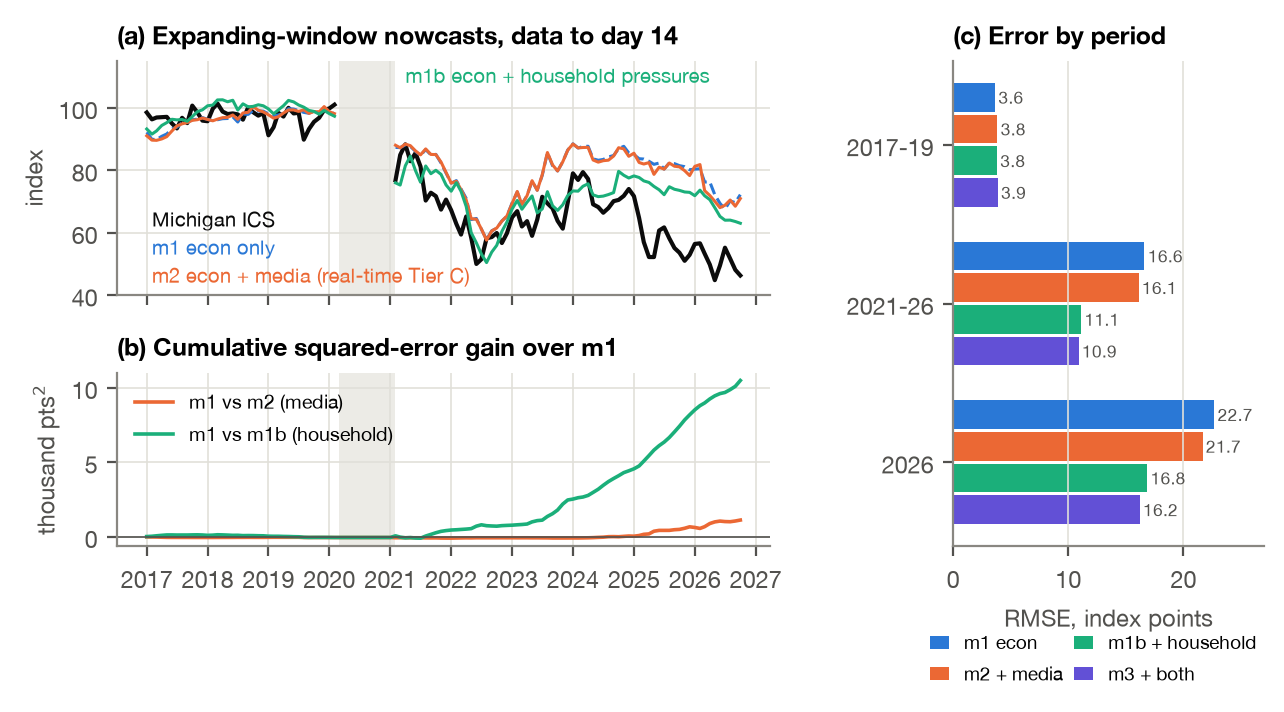

In [9]:
a = pd.read_csv(TABLES / 'rq5_accuracy.csv'); display(a.pivot_table(index=['dynamic', 'subperiod'], columns='model', values='rmse').round(2))
display(pd.read_csv(TABLES / 'rq5_clark_west.csv').round(4))
display(pd.DataFrame(R['rq5']['grid']).round(4)); print('grid hits:', R['rq5']['grid_hits_p_lt_0.10'], 'joint null:', R['rq5']['joint_null_hits'])
display(pd.DataFrame(R['rq5']['non_nested']).round(4))
print('EXPLORATORY (not pre-registered) m1 vs m1b:', json.dumps(R['rq5_exploratory_m1_vs_m1b'], indent=1))
display(Image(filename=str(FIGURES / 'fig5_prediction.png'), width=950))

**How the nowcasts are made.** On the prediction date of month t (day 14), each model is re-estimated on every earlier month (their sentiment values are all published by then) and applied to month t's real-time regressors. Model 1 uses the economy only, 1b adds the household-pressure controls, 2 adds the media measures to model 1, and 3 adds both. The Tier C media columns at origin t come from vintage t (scripts/09b): the classifier re-trained on codes published before day 15 of t and applied to every month up to t, so no code published after a nowcast's origin enters any value used at that origin. Accuracy is compared over the same months for every model. The Clark-West test asks whether the larger model's improvement is more than estimation noise would give (one-sided, HAC standard errors). The sensitivity grid swaps the media measure and the timing; its count of hits is compared with the count obtained after circularly shifting all media series by 13 to 57 months.

## 10. RQ6: What evidence would contradict a media-bias explanation?

*Readings used:* External: Gambetti et al. (2023) (no unemployment negativity bias once dynamics are allowed for); Mian et al. (2023); Sacerdote et al. (2020). Figure: Figures 3 and 4.

**Result.** I wrote seven falsifiers before testing. One holds clearly (F7), two partly (F2, F3), three do not (F1, F4, F6), and one cannot be settled with monthly data (F5); together with the breadth of the gap, the evidence leans against media bias as more than a small contributor.

**Table 7. Pre-registered falsifiers (true = evidence against media bias).**

| Falsifier | Rule | Result |
|---|---|---|
| F1 | No claim-rule pass and Clark-West p ≥ 0.10 for m2 vs m1 and m3 vs m1b | False: m2 vs m1 p = 0.053 |
| F2 | Sentiment leads media (TY q < 0.10) while media do not lead sentiment | Partly: false for Tier C; holds for SF Fed (q = 0.003 vs 0.80) |
| F3 | No negativity asymmetry | Partly: true for unemployment, false for inflation |
| F4 | Household controls close ≥ 50% of the gap in both samples (inconclusive if jointly p ≥ 0.10) | False: 6% in 1992 to 2019 (joint p < 0.001); -8% in 2010 to 2019 (joint p = 0.46, inconclusive there) |
| F5 | Party sentiment shifts at an election precede shifts in own-side media tone | Cannot be settled: 2024 party swings of 22 to 32 points in two months, partisan outlets' tone moved under 0.08 in the partisan direction, and 3-month windows cannot order them; 2020 cells too small |
| F6 | A survey-mode shift as large as the gap | False: 6.6 points, 17% of the gap |
| F7 | Recalled unfavourable news fits fundamentals better than coverage | True: R² 0.80 vs 0.61 |

**Table 8. Three-explanation scorecard (pre-registered rules).**

| Explanation | Rule result | Verdict |
|---|---|---|
| H1 pressures | Controls close -8% (2010 to 2019) and 6% (1992 to 2019) of the 2026 gap in fixed models; needed ≥ 50% in both | Not supported (by rule; the exploratory expanding-window m1b result points the other way) |
| H2 perceptions | Claim rule fails; Clark-West m2 vs m1 p = 0.053 (first run 0.037); media Shapley share of the gap closed: none (both blocks widen the gap: H1 -8.1%, media -1.5%) | Partly |
| H3 measurement and model | Mode 17% and revisions 3% (< 25% each); instability: coefficients change sign and fixed RMSE 29.2 > 1.25 × expanding 16.6 | Partly (literal, backwards rule: not supported) |

- **Breadth.** Jan to Aug 2026 gaps are -37 to -42 across income thirds, -38 to -45 across age groups and -33 to -41 across regions. Every party is far below 2017 to 2019: Democrats 78.8 to 38.1, independents 96.6 to 47.4, Republicans 120.2 to 89.7, even though Republicans hold the presidency and their outlets are no more negative under it.

*Against Gambetti et al. (2023):* like them I find no unemployment negativity bias once the asymmetric dynamics are allowed for; the asymmetry I do find is specific to inflation.

*Why this result:* if negative coverage were the main driver, the fall should be largest among readers of the most negative outlets and coverage should move first; instead every income, age and region group fell by similar amounts, both parties fell from their 2017 to 2019 levels (Republicans too, whose outlets were less negative under their own president), recall of bad price news follows fundamentals, and sentiment leads the SF Fed index. The parts that survive (inflation asymmetry, a small forecasting gain) are consistent with coverage amplifying a real price-level pressure.

**In short.** The strongest evidence against media bias is that the gap is broad, recall tracks fundamentals better than coverage, and sentiment leads the SF Fed news index; media framing of inflation is real but explains little.

In [10]:
print(json.dumps(R['rq6'], indent=1)); print(json.dumps(R['scorecard'], indent=1)); print(json.dumps(R['shapley'], indent=1))

{
 "F1_no_media_effect_or_gain": false,
 "F2_sentiment_leads_media": false,
 "F3_no_asymmetry": {
  "U": true,
  "pi": false
 },
 "F4_h1_closes_gap": false,
 "F4_shares": [
  -0.0821678698057835,
  0.06239018963059406
 ],
 "F5_party_timing": "see rq2.party_timing",
 "F6_mode_as_large_as_gap": false,
 "F6_ratio": 0.16545548806346483,
 "F7_recall_tracks_fundamentals_better": true,
 "F7_R2": {
  "fundamentals": 0.7951450948943816,
  "media": 0.6083666526616882
 }
}
{
 "H1": {
  "verdict": "not supported",
  "share_closed_2010_19": -0.0821678698057835,
  "share_closed_long": 0.06239018963059406
 },
 "H2": {
  "verdict": "partly",
  "claim_rule": false,
  "cw_p_m1_vs_m2": 0.0533581900806378,
  "media_shapley_share": null
 },
 "H3": {
  "verdict": "partly",
  "mode_share": 0.16545548806346483,
  "revision_share": 0.02805631413390806,
  "instability_intended_rule": true,
  "instability_literal_rule": false,
  "verdict_under_literal_rule": "not supported"
 }
}
{
 "gaps": {
  "": -39.8898826339

## 11. Monitoring the pre-election period

![Figure 6](outputs/figures/fig6_monitoring.png)
*Figure 6. (a) ICS (black; hollow: October preliminary) and Model E's prediction with its 95% bootstrap band, Jan 2025 to Oct 2026. (b) Weekly net negativity and "prices high" share of relevant 2026 headlines (Opus codes, equal weights over outlet groups, 11 to 32 items a week; display only, no test), with three events. (c) Change in the gap from June to October each year; orange: midterm years; light grey: 2020 (COVID window). Descriptive.*

- **Dashboard.** `dashboard/index.html` (self-contained, built by `scripts/12_build_dashboard.py`) shows sentiment and Model E with its band, the gap, media tone, framing, salience and calibration (monthly Tier C and SF Fed, 2026 own-Opus monthly and weekly), the economic releases and the event calendar, and source composition, missing months and the validation scores. `scripts/update.py` refreshes the economic data, the gap, the dictionary and Tier C series without any AI call; new Opus coding follows the documented batch step in the README.
- **Groups.** Income, age and region gaps are similar (Section 10). Party is a moderator (Democrats' ICS 38.1 vs Republicans' 89.7, Jan to Aug 2026) and a confounder: the Republican share of respondents fell from March 2025 with the change of administration (Michigan, Jul 2026), so the index moves with the partisan mix as well as with views. But an equal-weighted mean of the three party indexes fell from 98.5 (Feb 2017 to 2019) to 58.4 (Jan to Aug 2026), 40 points against 45 for the national index over the same months, so the changing mix explains at most a few points.
- **Survey method.** Michigan's move to web interviews (Apr to Jul 2024) lowers ICS by 6.6 points on its own parallel comparison; adding that back gives a mode-adjusted 2026 gap of -33.3, so mode explains 17% of the gap. Michigan's own report (Jul 2026) also finds the May 2026 low below the June 2022 web reading, so the record is not a mode artifact.
- **Election proximity.** From June to October the gap moved -1.0 on average in past midterm years and -5.3 in other years; 2026's -5.0 is ordinary. I do not attribute any 2026 change to the campaign.
- **Cutoff and update plan.** Data end Oct 12, 2026. Before election day: Sep CPI (Oct 14), Michigan final October (Oct 23), Q3 GDP advance and Sep PCE (Oct 29), October jobs and the November preliminary (Nov 6, interviews all before the election). After: November final (Nov 20, first post-election interviews), October PCE and Q3 second estimate (Nov 25), December preliminary (Dec 4), government funding expiry (Dec 11). Each release reruns `update.py` (the last month is one setting in `src/config.py`). The November final is the first reading with post-election interviews; a midterm does not change the White House, so a 2020- or 2024-style party flip is not expected, and any November move should be compared with past midterm years before it is put down to the election.

{
 "mode_adjusted_gap_2026": -33.289882633983076,
 "jun_to_oct_gap_change": {
  "2010": -8.699444832008496,
  "2011": -8.79835349316916,
  "2012": 7.282472502891366,
  "2013": -11.548221884538307,
  "2014": -2.766803660222422,
  "2015": -11.645863652466659,
  "2016": -5.617982264277742,
  "2017": 2.9358401625246415,
  "2018": -1.2733902008114484,
  "2019": -2.426535858514356,
  "2020": 2.2468265165618675,
  "2021": -17.47568753517609,
  "2022": 8.547396345170402,
  "2023": -2.5250727652944107,
  "2024": 0.35771527749082566,
  "2025": -8.878203277586145,
  "2026": -4.96761678626541
 },
 "midterm_years_mean": -1.048060586967991,
 "other_years_mean": -5.303626617101458,
 "2026_jun_to_oct": -4.96761678626541,
 "party_equal_weight": {
  "mean_2017feb_2019": 98.53809523809524,
  "mean_2026_jan_aug": 58.412499999999994,
  "ics_2017feb_2019": 96.99714285714288,
  "ics_2026_jan_aug": 52.162499999999994
 },
 "party_2026": {
  "2026-01-01 00:00:00": {
   "ICS_DEM": 41.0,
   "ICS_IND": 50.8,
   "I

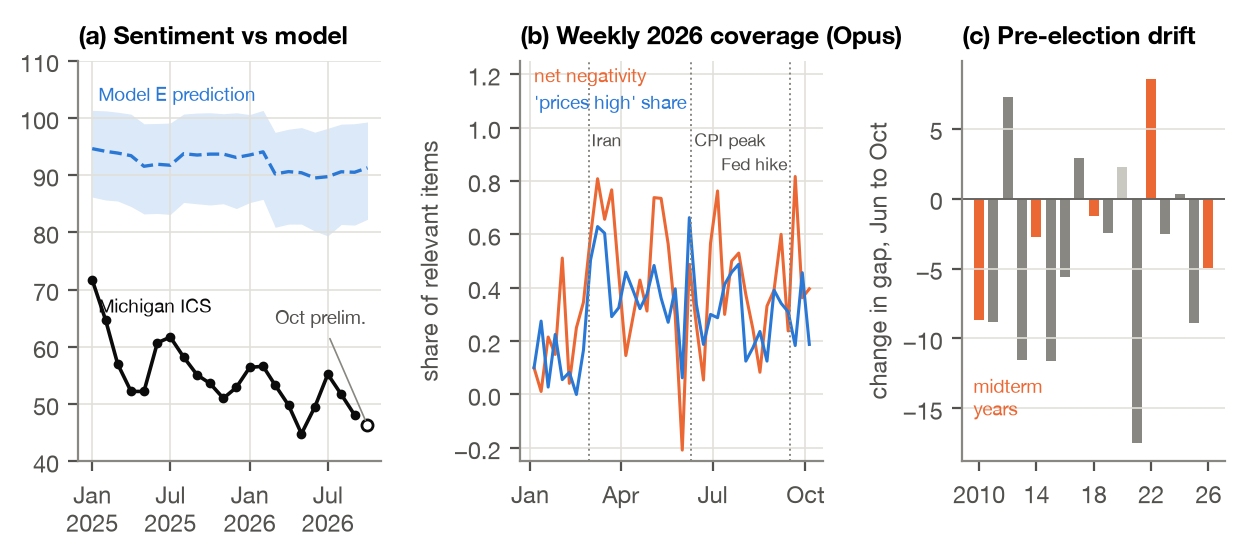

In [11]:
print(json.dumps(R['monitoring'], indent=1, default=str)[:5000])
display(Image(filename=str(FIGURES / 'fig6_monitoring.png'), width=950))

## 12. Conclusions

1. **The gap is real and large.** Sentiment is 39.9 points below an economy-only model in 2026 (N = 10 months, p < 0.0005, robust to six data variants). Robust.
2. **The headline indicators explain about a sixth** of the 2019 to 2026 fall (16%, CI 5% to 26%), and least of expected and current personal finances (6% and 8%) and buying conditions (14%). Robust.
3. **Prices, as a level, are the strongest single clue.** "Worse off because of prices" fits the price level against trend (R² 0.81, partly a contrast between regimes) far better than the inflation rate (0.41), and in an exploratory expanding-window test six household-pressure controls cut out-of-sample error by a third (RMSE 13.5 to 9.2). An association; that pressure, not perception, is behind it is a hypothesis.
4. **Coverage over-weights rising inflation** (asymmetry p = 0.002; a third of stories say "rising" in falling months) but shows no detectable asymmetry on jobs and gets most jobs numbers right. Fairly robust (N = 191 months; p = 0.019 without 2020 to 2021).
5. **No detectable depressing impact of media bias.** Taken as causal, Tier C negativity accounts for -1.0 point (90% bound -2.4) of a -39.9 gap; the claim rule fails; sentiment leads the SF Fed index. Noisy monthly tone (F1 0.63) biases toward zero, but the bound is small next to 40 points.
6. **Partisanship is a large, separate factor.** In 2024 party sentiment swung 22 to 32 points within two months of the election with fundamentals flat. One event, descriptive.
7. **What a portfolio manager should take away.** Do not read record-low Michigan sentiment as a signal of weaker consumer spending on its own: in this sample neither sentiment nor the gap predicted real spending (E1 below, exploratory; recession risk itself was not tested), and the gap looks mostly price-level and partisan. For nowcasting sentiment itself, put household-pressure variables in before news tone.

**Extra questions that came up (exploratory: not in the pre-registration).** *Readings used:* External: Carroll, Fuhrer and Wilcox (1994); Mian et al. (2023).
- **E1. Does the gap forecast spending?** *Result:* No. ICS and the out-of-sample gap do not predict real PCE growth 1 or 3 months ahead beyond the economy (p = 0.25 to 0.36; N = 66 to 188; a null of modest power, not proof of no link). *Why this result:* partisan and price-level pessimism need not change what households can spend, as Mian et al. found for partisan expectations. *In short:* the 2026 gloom has not been a spending signal.
- **E2. Do consumers recall what the media cover?** *Result:* For prices yes (r = 0.78), for jobs much less (layoffs 0.15, hiring 0.29); falling prices 0.41. *Why this result:* price news echoes what people see at the till, job news does not. *In short:* recall and coverage agree where both follow everyday experience.

In [12]:
print(json.dumps(R['extras'], indent=1))

{
 "E1_h1_ICS": {
  "N": 188,
  "coef": -0.006323731857286108,
  "p": 0.3612150110506036,
  "sample": [
   "2010-01-01",
   "2026-07-01"
  ]
 },
 "E1_h1_gap": {
  "N": 68,
  "coef": -0.036480581840579535,
  "p": 0.268458031616877,
  "sample": [
   "2020-01-01",
   "2026-07-01"
  ]
 },
 "E1_h3_ICS": {
  "N": 186,
  "coef": -0.007842955402728568,
  "p": 0.300239123727843,
  "sample": [
   "2010-01-01",
   "2026-05-01"
  ]
 },
 "E1_h3_gap": {
  "N": 66,
  "coef": -0.05020895703219237,
  "p": 0.2539400076779659,
  "sample": [
   "2020-01-01",
   "2026-05-01"
  ]
 },
 "E2_recall_vs_coverage": [
  {
   "media": "tc_prices_high",
   "recall": "unfav_high_prices",
   "N": 189,
   "r_levels": 0.7799786232081544,
   "r_changes": 0.3891844553142989
  },
  {
   "media": "tc_layoffs",
   "recall": "unfav_unemp",
   "N": 189,
   "r_levels": 0.14755611076864408,
   "r_changes": 0.10255602455240762
  },
  {
   "media": "tc_hiring",
   "recall": "fav_emp",
   "N": 189,
   "r_levels": 0.2888317206911024

## 13. Limitations and ethics

- **LLM labels, not human labels.** The gold set was labelled by Opus instances, so agreement is an upper bound and the coder may share the annotators' blind spots; the 0.38 tone F1 on the 11 items where the annotators disagreed on tone shows the risk. Relabelling the 450 items by two people with the guide is the first thing to do with more time.
- **LLM look-ahead.** Opus knows what happened after 2010 to 2025 and may code old headlines with hindsight (Glasserman and Lin 2023). Items were shown without dates, and the dictionary and SF Fed series are hindsight-free checks; results agree in sign but this cannot be ruled out.
- **Headlines only, sampled.** Google's 100-item cap makes each window a relevance-ranked sample; no article text; Reddit is a narrow, self-selected audience; exposure is not observed.
- **Thin history coding.** A usage limit and a 38% relevance rate made the own-Opus series quarterly; the monthly tests use Tier C, which is noisier (tone F1 0.63) and biases toward zero. The in-sample tests (asymmetry, level model, Granger) and the Shapley split use the Tier C series from one classifier trained on all codes; only the out-of-sample tests use the real-time version.
- **Evidence quotes and text.** Every code's verbatim evidence quote is kept in `data/coded/codes.parquet` and the batch outputs, but not in the repo, because they are headline text; the repo has the codes without text.
- **Model scope.** Model E is linear and trained on a decade without price-level shocks; I did not build Bolhuis et al.'s cost-of-money index. Six household controls is a manageable set, not a complete one. Party is handled descriptively (party indexes, an equal-weighted check), not by reweighting respondents.
- **Ethics.** Public or licensed data only; no human-subject research was run (the experiment is a proposal and needs IRB approval before fielding); Reddit usernames hashed at download and never stored; no headline or post text is redistributed (the repo has codes and ids, not text). One privacy slip: a verification subagent put my NYU email in one request header to bls.gov; it is disclosed in AI_USE.md.

## 14. References

<p class="refs"><b>Class readings.</b> Sacerdote, B., Sehgal, R., Cook, M. (2020). Why Is All COVID-19 News Bad News? NBER WP 28110. · Bybee, L., Kelly, B., Manela, A., Xiu, D. (2024). Business News and Business Cycles. J. Finance 79(5): 3105-3147. · Loughran, T., McDonald, B. (2011). When Is a Liability Not a Liability? J. Finance 66(1): 35-65. · Psomakelis, E. et al. (2014). Comparing Methods for Twitter Sentiment Analysis. KDIR. · Carvalho, J., Plastino, A. (2020). On the Evaluation and Combination of State-of-the-Art Features in Twitter Sentiment Analysis. Artificial Intelligence Review. · Souza, T. et al. (2015). Twitter Sentiment Analysis Applied to Finance: A Case Study in the Retail Industry. · Jurafsky, D., lecture slides on sentiment, citing O'Connor, B., Balasubramanyan, R., Routledge, B., Smith, N. (2010). From Tweets to Polls. ICWSM 4(1): 122-129.<br>
<b>External.</b> Bolhuis, M., Cramer, J., Schulz, K., Summers, L. (2024). The Cost of Money is Part of the Cost of Living. NBER WP 32163. · Shapiro, A., Sudhof, M., Wilson, D. (2022). Measuring News Sentiment. J. Econometrics 228(2): 221-243. · Buckman, S., Shapiro, A., Sudhof, M., Wilson, D. (2020). News Sentiment in the Time of COVID-19. FRBSF Economic Letter 2020-08. · Doms, M., Morin, N. (2004). Consumer Sentiment, the Economy, and the News Media. FRBSF WP 2004-09. · Soroka, S. (2006). Good News and Bad News. J. Politics 68(2): 372-385. · Gambetti, L., Maffei-Faccioli, N., Zoi, S. (2023). Bad News, Good News: Coverage and Response Asymmetries. FEDS 2023-001. · Harris, B., Sojourner, A. (2024). Why are Americans so displeased with the economy? Brookings, Jan 5. · Gentzkow, M., Shapiro, J. (2010). What Drives Media Slant? Econometrica 78(1): 35-71. · Stantcheva, S. (2024). Why Do We Dislike Inflation? BPEA Spring: 1-46. · D'Acunto, F., Malmendier, U., Ospina, J., Weber, M. (2021). Exposure to Grocery Prices and Inflation Expectations. JPE 129(5): 1615-1639. · Malmendier, U., Nagel, S. (2016). Learning from Inflation Experiences. QJE 131(1): 53-87. · Mian, A., Sufi, A., Khoshkhou, N. (2023). Partisan Bias, Economic Expectations, and Household Spending. REStat 105(3): 493-510. · Carroll, C. (2003). Macroeconomic Expectations of Households and Professional Forecasters. QJE 118(1): 269-298. · Carroll, C., Fuhrer, J., Wilcox, D. (1994). Does Consumer Sentiment Forecast Household Spending? AER 84(5): 1397-1408. · Baker, S., Bloom, N., Davis, S. (2016). Measuring Economic Policy Uncertainty. QJE 131(4): 1593-1636. · Lazarus, E., Lewis, D., Stock, J., Watson, M. (2018). HAR Inference: Recommendations for Practice. JBES 36(4): 541-559. · Newey, W., West, K. (1987). Econometrica 55(3): 703-708. · Künsch, H. (1989). Ann. Statist. 17(3): 1217-1241. · Clark, T., West, K. (2007). J. Econometrics 138(1): 291-311. · Diebold, F., Mariano, R. (1995). JBES 13(3): 253-263. · Harvey, D., Leybourne, S., Newbold, P. (1997). IJF 13(2): 281-291. · Toda, H., Yamamoto, T. (1995). J. Econometrics 66(1-2): 225-250. · Granger, C. (1969). Econometrica 37(3): 424-438. · Benjamini, Y., Hochberg, Y. (1995). JRSS-B 57(1): 289-300. · Cohen, J. (1960). Educ. Psychol. Meas. 20(1): 37-46. · Landis, J., Koch, G. (1977). Biometrics 33(1): 159-174. · Krippendorff, K. (2004). Content Analysis, 2nd ed. · Gwet, K. (2008). Br. J. Math. Stat. Psychol. 61(1): 29-48. · Cinelli, C., Hazlett, C. (2020). JRSS-B 82(1): 39-67. · Hulley, S. et al. (2013). Designing Clinical Research, 4th ed. · Glasserman, P., Lin, C. (2023). Assessing Look-Ahead Bias in Stock Return Predictions Generated by GPT Sentiment Analysis. arXiv:2309.17322.<br>
<b>Data and facts.</b> University of Michigan Surveys of Consumers (sca.isr.umich.edu; data.sca.isr.umich.edu tables; technical documentation of the web transition, docid 75437, Apr 5, 2024; "Sentiment, Web-Based Data Collection, and Partisanship", Jul 10, 2026; "Gasoline Prices and Expected Consumer Spending", Oct 9, 2026, for the Iran conflict date). · BLS (LNS14000000; Employment Situation and CPI releases; 2025 lapse release dates). · BEA (PCE, GDP; release schedule). · ALFRED and FRED, Federal Reserve Bank of St. Louis (18 series; ids in src/config.py and docs/CORPUS.md). · SF Fed Daily News Sentiment Index. · Economic Policy Uncertainty, news-based index (policyuncertainty.com). · Atlanta Fed GDPNow. · Google News RSS. · Arctic Shift Reddit archive. · AllSides media bias ratings. · Pew Research Center (2025), The Political Gap in Americans' News Sources, Jun 10. · Events: Federal Reserve press releases (Jan 28, May 22, Sep 16, 2026); Supreme Court, Learning Resources v. Trump (Feb 20, 2026); Federal Register (Proclamation 11012; Section 301 actions, Jul 2026); EIA weekly retail gasoline; BLS Employment Situation (Mar 6, Oct 2, 2026) and CPI (Jun 10, 2026); CRS R41759 (shutdowns); White House (H.R. 6500, Sep 2, 2026). · Course file Perceptual_Bias_Data.xlsx. · AI: Claude Opus 5.5 (claude-opus-5-5) via Claude Code, Anthropic.</p>